---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Kelompok G13 Brownbear

- Wafiq Hibban Robbany (13524016)
- Moh. Hafizh Irham Perdana (13524025)
- Wildan Abdurrahman Ghazali (13524054)
- A. Fawwaz Azam Wicaksono (13524070)
- Zahran Alvan Putra Winarko (13524124)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pemesanan yang dibatalkan meninggalkan kamar kosong yang sebenarnya masih bisa dijual ke tamu lain. Jika pembatalan dapat diprediksi lebih awal, penginapan dapat merencanakan *overbooking*, mengirim pengingat, dan menyesuaikan kebijakan pembatalan.

## Aim

Kami membangun model klasifikasi yang memprediksi `is_canceled` (1 = batal, 0 = tidak batal). KNN, Decision Tree Learning, Logistic Regression, SVM, dan Naive Bayes diimplementasikan dari awal, dibandingkan dengan pasangan scikit-learn, lalu model terbaik dipakai untuk submisi Kaggle.

## Metric

Metrik utama adalah macro F1, yaitu rata-rata F1 kelas batal dan kelas tidak batal. Kedua kelas berbobot sama, sehingga ambang keputusan (*threshold*) juga disetel agar kelas batal yang lebih sedikit tidak terabaikan.

## Dataset

Data training berisi 27.373 pemesanan dengan 17 fitur dan target `is_canceled`, sedangkan data test berisi 6.844 pemesanan tanpa label. Fitur mencakup jumlah tamu, lama menginap, paket makan, kategori kamar, kanal pemesanan, harga per malam, dan riwayat tamu. Delapan kolom memiliki nilai kosong, dan ID pemesanan dipertahankan sebagai teks.

## Approach

1. Data diperiksa terlebih dahulu, lalu data training dibagi menjadi training dan validasi tanpa memisahkan baris fitur yang identik.
2. Setiap pipeline hanya di-fit pada bagian training, lalu dipakai untuk mentransformasi validasi dan test.
3. Kelima model mula-mula dibandingkan pada lima ribu baris training yang sama. Setelah itu, setiap model disetel dengan preprocessing yang sesuai dengan cara kerjanya serta hyperparameter dan threshold yang dipilih lewat cross-validation pada data training, lalu dinilai sekali pada data validasi. Naive Bayes juga diperluas menjadi Tree-Augmented Naive Bayes agar ketergantungan antarfitur ikut dimodelkan.
4. Model akhir adalah KNN dengan jarak Manhattan berbobot ditambah penalti untuk atribut diskret yang berbeda. Pilihan ini didasarkan pada temuan bahwa banyak pemesanan memiliki pemesanan lain yang serupa dengan label yang sama.
5. Model akhir dilatih ulang pada seluruh data training. Tiga konfigurasi KNN dipakai sebagai submisi final Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import pickle
import random
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Video, display
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score,
    mutual_info_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

if (Path.cwd() / 'data/train.csv').is_file():
    os.chdir('src')
sys.path.insert(0, str(Path.cwd()))

from brownbear.models import (
    KNN, SVM, DecisionTree, LogisticRegression, NaiveBayes, TreeAugmentedNaiveBayes,
)
from brownbear.preprocessing import (
    BINARY_COLUMNS, CATEGORICAL_COLUMNS, DISCRETE_COLUMNS, FEATURE_COLUMNS, KNN_FEATURE_WEIGHTS,
    KNN_MISMATCH_PENALTIES, NUMERIC_COLUMNS, SIBLING_KEY, SiblingImputer, add_knn_features,
    impute_from_siblings, make_basic_preprocessor, make_discrete_preprocessor, make_knn_preprocessor,
    make_linear_preprocessor, make_numeric_preprocessor, make_svm_preprocessor, make_tree_preprocessor,
    select_features, split_training_data,
)
from brownbear.visualization import (
    plot_bayesian_network, plot_decision_tree, plot_kernels,
    save_logistic_regression_animation,
)

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('../data')
    OUTPUT_DIR = Path('../output')

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
description = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'unique': train_df.nunique(dropna=True),
    'missing': train_df.isna().sum(),
})
print(description)
print(train_df[NUMERIC_COLUMNS].describe().T)

                            dtype  unique  missing
id                            str   27373        0
num_adults                float64       5      809
num_children              float64       6     3035
weekend_nights              int64       8        0
weekday_nights              int64      18        0
meal_package                  str       4     1760
needs_parking             float64       2     1082
room_category                 str       7     1002
days_before_arrival       float64     407     1123
arrival_year                int64       2        0
arrival_month               int64      12        0
arrival_day                 int64      31        0
booking_channel               str       5        0
is_returning_guest          int64       2        0
prior_cancellations         int64       9        0
prior_completed_bookings    int64      52        0
nightly_rate_idr          float64    2787     2038
special_requests          float64       6     2500
is_canceled                 int

Data training berisi 17 fitur: dua belas numerik (jumlah tamu, lama menginap, lead time, tanggal kedatangan, riwayat tamu, harga, dan permintaan khusus), dua biner (`needs_parking` dan `is_returning_guest`), serta tiga kategorikal berupa teks (`meal_package`, `room_category`, dan `booking_channel`). Delapan kolom memiliki nilai kosong, paling banyak pada `num_children` (11,1%), `special_requests` (9,1%), dan `nightly_rate_idr` (7,4%). `days_before_arrival` dan `nightly_rate_idr` sangat miring: median lead time 58 hari tetapi maksimumnya 448 hari, sedangkan median harga Rp1,64 juta dengan maksimum Rp9,17 juta. Riwayat pembatalan dan pemesanan sebelumnya hampir selalu nol.

## Explore Data

This part covers distributions and relationships between attributes.

In [7]:
print(train_df['is_canceled'].value_counts().sort_index().rename('count').to_frame())
for column in CATEGORICAL_COLUMNS:
    print(column, train_df[column].value_counts(dropna=False).to_dict())

lead_bins = pd.cut(train_df['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
print(train_df.groupby(lead_bins, observed=True)['is_canceled'].agg(['size', 'mean']).round(3))
print(train_df.groupby('special_requests')['is_canceled'].agg(['size', 'mean']).round(3))

sibling_key = SIBLING_KEY + ['days_before_arrival', 'booking_channel', 'num_adults']
siblings = train_df.groupby(sibling_key)['is_canceled'].agg(['size', 'mean'])
shared = siblings[siblings['size'] > 1]
print('Pemesanan dalam kelompok saudara:', int(shared['size'].sum()))
print('Kelompok dengan label seragam:',
      round(shared.loc[shared['mean'].isin([0, 1]), 'size'].sum() / shared['size'].sum(), 3))
print('Data test yang punya saudara persis di training:',
      round(test_df[sibling_key].merge(siblings.reset_index(), on=sibling_key, how='left')['size'].notna().mean(), 3))

             count
is_canceled       
0            18404
1             8969
meal_package {'Breakfast': 19654, 'Room Only': 3713, 'Half Board': 2242, nan: 1760, 'Full Board': 4}
room_category {'Type B': 20447, 'Type G': 4396, nan: 1002, 'Type A': 699, 'Type D': 514, 'Type C': 189, 'Type F': 119, 'Type E': 7}
booking_channel {'Online Travel Agent': 17511, 'Offline Agent': 7960, 'Corporate': 1513, 'Complimentary': 301, 'Airline': 88}
                     size   mean
days_before_arrival             
(-1, 7]              4116  0.096
(7, 30]              4868  0.183
(30, 90]             7847  0.253
(90, 180]            5573  0.451
(180, 500]           3846  0.736
                   size   mean
special_requests              
0.0               12730  0.432
1.0                8334  0.238
2.0                3246  0.143
3.0                 496  0.000
4.0                  60  0.000
5.0                   7  0.000
Pemesanan dalam kelompok saudara: 5658
Kelompok dengan label seragam: 0.862
Data test 

Pembatalan meningkat tajam seiring bertambahnya `days_before_arrival`, sedangkan pemesanan dengan permintaan khusus lebih jarang batal. Selain itu, banyak pemesanan memiliki pemesanan serupa, yaitu pemesanan lain dengan tanggal kedatangan, lama menginap, kanal, dan jumlah dewasa yang sama. Sekitar 86% kelompok pemesanan serupa memiliki label yang seragam. `days_before_arrival` dan harga di antara pemesanan serupa sering sedikit berbeda, sehingga pencocokan persis menghitung jumlahnya terlalu sedikit. Pola lokal ini menjadi alasan utama kami mengembangkan KNN.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
raw_train = select_features(train_df)
raw_test = select_features(test_df)
quality = pd.DataFrame(index=FEATURE_COLUMNS)
quality['train_missing'] = raw_train.isna().sum()
quality['train_missing_pct'] = raw_train.isna().mean().mul(100)
quality['test_missing'] = raw_test.isna().sum()
quality['test_missing_pct'] = raw_test.isna().mean().mul(100)
print(quality.loc[quality[['train_missing', 'test_missing']].sum(axis=1) > 0].round(2))
print('Nilai dan tanggal kedatangan lolos validasi.')

                     train_missing  train_missing_pct  test_missing  \
num_adults                     809               2.96           180   
num_children                  3035              11.09           747   
days_before_arrival           1123               4.10           290   
nightly_rate_idr              2038               7.45           540   
special_requests              2500               9.13           593   
needs_parking                 1082               3.95           247   
meal_package                  1760               6.43           442   
room_category                 1002               3.66           242   

                     test_missing_pct  
num_adults                       2.63  
num_children                    10.91  
days_before_arrival              4.24  
nightly_rate_idr                 7.89  
special_requests                 8.66  
needs_parking                    3.61  
meal_package                     6.46  
room_category                    3.54  


Delapan fitur memiliki nilai kosong pada data latih dan data uji. Karena target tersedia hanya pada data latih, data uji disimpan khusus untuk submission.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
train_idx, val_idx = split_training_data(train_df, seed=CFG.SEED)
train_set, val_set = train_df.iloc[train_idx].copy(), train_df.iloc[val_idx].copy()
groups = raw_train.groupby(FEATURE_COLUMNS, dropna=False, sort=False).ngroup()
assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[val_idx])
assert sorted(np.r_[train_idx, val_idx]) == list(range(len(train_df)))
assert set(train_set['is_canceled']) == set(val_set['is_canceled']) == {0, 1}
split_summary = pd.DataFrame({
    name: {'rows': len(frame), 'canceled': int(frame['is_canceled'].sum()),
           'canceled_pct': frame['is_canceled'].mean() * 100}
    for name, frame in [('training', train_set), ('validation', val_set)]
}).T
print(split_summary.round(3))

               rows  canceled  canceled_pct
training    21899.0    7175.0        32.764
validation   5474.0    1794.0        32.773


Proporsi pembatalan hampir sama pada kedua bagian data. Pemisahan berdasarkan kelompok fitur juga mencegah baris yang identik berpindah ke validasi.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
X_train_raw, X_val_raw = select_features(train_set), select_features(val_set)
y_train = train_set['is_canceled'].astype(int)
y_val = val_set['is_canceled'].astype(int)
test_ids = test_df['id'].copy()
assert not X_train_raw.isna().all().any(), 'Ada fitur yang seluruhnya kosong.'
print('Ketujuh belas fitur dipakai; ID dan target disimpan terpisah.')

Ketujuh belas fitur dipakai; ID dan target disimpan terpisah.

In [11]:
# Relevansi fitur: mutual information setiap fitur terhadap target, dihitung dari train_set saja.
# Fitur kontinu dibagi ke dalam 10 bin kuantil agar dapat dihitung seperti fitur kategorikal.
relevance_prep = make_discrete_preprocessor(n_bins=10).fit(train_set)
X_relevance = relevance_prep.transform(train_set)
feature_relevance = pd.Series(
    [mutual_info_score(y_train, X_relevance[:, column]) for column in range(len(DISCRETE_COLUMNS))],
    index=DISCRETE_COLUMNS, name='mutual_information',
).sort_values(ascending=False)
print(feature_relevance.round(4).to_string())

days_before_arrival         0.0975
special_requests            0.0365
arrival_month               0.0245
arrival_year                0.0184
nightly_rate_idr            0.0151
booking_channel             0.0136
is_returning_guest          0.0083
prior_completed_bookings    0.0082
weekday_nights              0.0067
num_adults                  0.0048
needs_parking               0.0043
arrival_day                 0.0034
meal_package                0.0034
weekend_nights              0.0029
prior_cancellations         0.0026
room_category               0.0008
num_children                0.0008


`days_before_arrival` adalah fitur paling informatif terhadap pembatalan, dengan *mutual information* sekitar 2,7 kali `special_requests` di urutan kedua. Setelahnya ada bulan dan tahun kedatangan, harga, serta kanal pemesanan. `room_category` dan `num_children` hampir tidak informatif jika dilihat sendiri-sendiri.

Ketujuh belas fitur tetap dipertahankan pada tahap ini. *Mutual information* hanya mengukur hubungan satu fitur dengan target, padahal fitur yang lemah jika dilihat sendiri dapat berguna bila digabung dengan fitur lain. Misalnya, `room_category` dan `num_children` membantu mengenali pemesanan serupa pada KNN. Seleksi fitur yang sesungguhnya dilakukan oleh setiap model: bobot fitur KNN (fitur berbobot 0, seperti `num_children` dan `arrival_year`, tidak masuk jarak berbobot), regularisasi L1 pada Logistic Regression, dan pemilihan split pada DTL. ID tidak dipakai karena hanya berupa kode unik tanpa informasi tentang pemesanan.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [12]:
prep = make_basic_preprocessor()
X_train = prep.fit_transform(X_train_raw)
X_val = prep.transform(X_val_raw)
X_test = prep.transform(raw_test)
imputer = prep.named_steps['impute']
fills = pd.DataFrame({'feature': NUMERIC_COLUMNS + BINARY_COLUMNS,
                     'strategy': ['median'] * len(NUMERIC_COLUMNS) + ['mode'] * len(BINARY_COLUMNS),
                     'value': np.r_[imputer.named_transformers_['numeric'].statistics_,
                                    imputer.named_transformers_['binary'].statistics_]})
print(fills)
print('Nilai kosong setelah preprocessing:', {name: int(frame.isna().sum().sum())
      for name, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]})

rng = np.random.default_rng(CFG.SEED)
known_lead = X_train_raw.index[X_train_raw['days_before_arrival'].notna()]
hidden = rng.choice(known_lead, 1000, replace=False)
probe = X_train_raw.loc[hidden].assign(days_before_arrival=np.nan)
truth = X_train_raw.loc[hidden, 'days_before_arrival']
sibling_guess = impute_from_siblings(X_train_raw.drop(hidden), probe)
median_guess = X_train_raw.drop(hidden)['days_before_arrival'].median()
print('MAE imputasi days_before_arrival dari saudara:', round((sibling_guess - truth).abs().mean(), 1), 'hari')
print('MAE imputasi days_before_arrival dari median :', round((median_guess - truth).abs().mean(), 1), 'hari')

                     feature strategy      value
0                 num_adults   median        2.0
1               num_children   median        0.0
2             weekend_nights   median        1.0
3             weekday_nights   median        2.0
4        days_before_arrival   median       58.0
5               arrival_year   median     2024.0
6              arrival_month   median        8.0
7                arrival_day   median       16.0
8        prior_cancellations   median        0.0
9   prior_completed_bookings   median        0.0
10          nightly_rate_idr   median  1648000.0
11          special_requests   median        0.0
12             needs_parking     mode        0.0
13        is_returning_guest     mode        0.0
Nilai kosong setelah preprocessing: {'train': 0, 'validation': 0, 'test': 0}


MAE imputasi days_before_arrival dari saudara: 29.9 hari
MAE imputasi days_before_arrival dari median : 61.6 hari


Nilai numerik diisi dengan median, sedangkan penanda biner diisi dengan modus. Kategori yang kosong diberi label khusus agar tetap dapat dibedakan. Semua nilai pengganti dihitung dari data training saja.

Khusus untuk KNN, `days_before_arrival` yang kosong diisi dari pemesanan serupa yang paling mirip di data training, yaitu pemesanan dengan tanggal kedatangan dan lama menginap yang sama. Uji dengan 1.000 nilai yang sengaja disembunyikan menunjukkan error imputasi ini sekitar setengah dari error imputasi median. Pada penalti jarak KNN, nilai kosong tidak dianggap berbeda sehingga baris tersebut tidak diberi penalti dua kali.

### Duplicates

This part covers repeated records.

In [13]:
duplicate_summary = {
    'repeated_ids_train': int(train_df['id'].duplicated().sum()),
    'repeated_records_excluding_id': int(train_df.drop(columns='id').duplicated().sum()),
    'repeated_feature_rows': int(raw_train.duplicated().sum()),
    'conflicting_feature_groups': int(train_df.groupby(
        FEATURE_COLUMNS, dropna=False)['is_canceled'].nunique().gt(1).sum()),
    'shared_raw_groups_train_val': len(set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])),
}
print(duplicate_summary)
print('Baris fitur yang berulang tetap disimpan sebagai pemesanan terpisah.')

{'repeated_ids_train': 0, 'repeated_records_excluding_id': 64, 'repeated_feature_rows': 66, 'conflicting_feature_groups': 2, 'shared_raw_groups_train_val': 0}
Baris fitur yang berulang tetap disimpan sebagai pemesanan terpisah.


Semua ID pemesanan berbeda, tetapi beberapa baris fitur memang berulang. Baris tersebut tetap disimpan karena dua kelompok fitur bahkan memiliki label yang berbeda.

### Outliers

This part covers values far from the rest of the data.

                             median         p99        max    skew       iqr  \
num_adults                      2.0        3.00        4.0  -0.312       0.0   
num_children                    0.0        2.00       10.0   4.902       0.0   
weekend_nights                  1.0        2.02        7.0   0.763       2.0   
weekday_nights                  2.0        6.00       17.0   1.685       2.0   
days_before_arrival            58.0      345.00      448.0   1.302     110.0   
arrival_year                 2024.0     2024.00     2024.0  -1.662       0.0   
arrival_month                   8.0       12.00       12.0  -0.349       5.0   
arrival_day                    16.0       31.00       31.0   0.036      15.0   
prior_cancellations             0.0        0.00       13.0  26.059       0.0   
prior_completed_bookings        0.0        4.00       58.0  20.416       0.0   
nightly_rate_idr          1648000.0  3456350.00  6338000.0   0.587  683000.0   
special_requests                0.0     

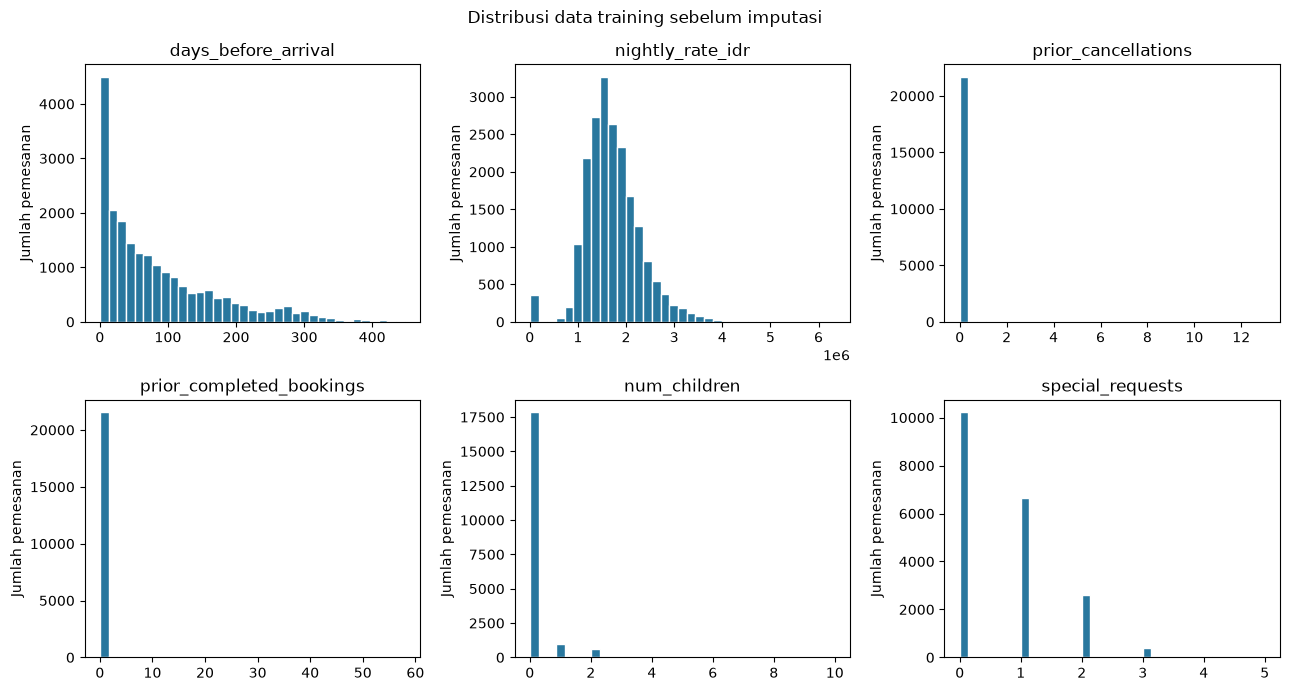

In [14]:
numeric = X_train_raw[NUMERIC_COLUMNS]
q1, q3 = numeric.quantile(.25), numeric.quantile(.75)
iqr = q3 - q1
outlier_review = pd.DataFrame({'median': numeric.median(), 'p99': numeric.quantile(.99),
                              'max': numeric.max(), 'skew': numeric.skew(), 'iqr': iqr,
                              'zero_pct': numeric.eq(0).sum() / numeric.notna().sum() * 100,
                              'outside_iqr': ((numeric < q1 - 1.5 * iqr) |
                                              (numeric > q3 + 1.5 * iqr)).sum()})
print(outlier_review.round(3))
plot_columns = ['days_before_arrival', 'nightly_rate_idr', 'prior_cancellations',
                'prior_completed_bookings', 'num_children', 'special_requests']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for column, ax in zip(plot_columns, axes.flat):
    ax.hist(numeric[column].dropna(), bins=35, color='#28779e', edgecolor='white')
    ax.set_title(column)
    ax.set_ylabel('Jumlah pemesanan')
fig.suptitle('Distribusi data training sebelum imputasi')
fig.tight_layout()
plt.show()

Aturan IQR menandai banyak nilai nol pada beberapa fitur hitungan. Nilai tersebut masih masuk akal, sehingga kami tidak menghapus baris hanya karena melewati batas IQR.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [15]:
audit_counts = {}
for name, frame in [('training', X_train_raw), ('validation', X_val_raw), ('test', raw_test)]:
    audit_counts[name] = {
        'zero_rate': int(frame['nightly_rate_idr'].eq(0).sum()),
        'zero_total_nights': int((frame['weekend_nights'] + frame['weekday_nights']).eq(0).sum()),
        'known_zero_total_guests': int((frame['num_adults'] + frame['num_children']).eq(0).sum()),
    }
print(pd.DataFrame(audit_counts).T)
print('Harga nol dan masa inap nol tetap dipertahankan.')

            zero_rate  zero_total_nights  known_zero_total_guests
training          330                 56                        0
validation         83                  8                        0
test               85                  9                        0
Harga nol dan masa inap nol tetap dipertahankan.


Harga nol dan masa inap nol ditemukan pada sebagian pemesanan. Nilai tersebut dipertahankan karena tidak ada bukti bahwa semuanya merupakan kesalahan pencatatan.

## Construct Data

Construction derives attributes and transforms values for modeling.

<!-- rubric v3: derived columns, rate_per_guest_night -->

### Attribute Construction

This part covers new attributes derived from existing ones.

In [16]:
knn_features = add_knn_features(X_train_raw)
derived_columns = ['month_sin', 'month_cos', 'log_lead', 'booking_ordinal', 'log_rate']
print(knn_features[derived_columns].describe().T.round(3))
booking_bins = pd.qcut(knn_features['booking_ordinal'], 5)
print(y_train.groupby(booking_bins, observed=True).mean().rename('canceled_rate').round(3))

                   count     mean      std   min      25%      50%      75%  \
month_sin        21899.0   -0.206    0.705  -1.0   -0.866   -0.500    0.500   
month_cos        21899.0   -0.036    0.677  -1.0   -0.500   -0.000    0.500   
log_lead         20998.0    3.729    1.486   0.0    2.890    4.078    4.852   
booking_ordinal  20998.0  422.914  146.343 -81.0  337.000  416.000  527.000   
log_rate         20254.0   14.092    1.843   0.0   14.109   14.315   14.521   

                     max  
month_sin          1.000  
month_cos          1.000  
log_lead           6.107  
booking_ordinal  727.000  
log_rate          15.662  
booking_ordinal
(-81.001, 296.0]    0.299
(296.0, 390.0]      0.400
(390.0, 454.0]      0.410
(454.0, 561.0]      0.338
(561.0, 727.0]      0.191
Name: canceled_rate, dtype: float64


Matriks dasar tetap memakai tujuh belas fitur asli. Untuk SVM dan KNN, kami menambahkan fitur turunan dari tanggal kedatangan, lama pemesanan, dan harga:

- `booking_ordinal` adalah tanggal pemesanan, yaitu tanggal kedatangan dikurangi `days_before_arrival`. Pemesanan untuk satu grup biasanya dibuat pada hari yang sama, sehingga fitur ini membantu KNN menemukan pemesanan serupa.
- `month_sin` dan `month_cos` membuat bulan bersifat siklikal, sehingga Desember berdekatan dengan Januari.
- `log_lead` dan `log_rate` mengurangi kemiringan distribusi lama pemesanan dan harga.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [17]:
print(X_train[NUMERIC_COLUMNS + BINARY_COLUMNS].agg(['min', 'max']).T)

                             min        max
num_adults                   0.0        4.0
num_children                 0.0       10.0
weekend_nights               0.0        7.0
weekday_nights               0.0       17.0
days_before_arrival          0.0      448.0
arrival_year              2023.0     2024.0
arrival_month                1.0       12.0
arrival_day                  1.0       31.0
prior_cancellations          0.0       13.0
prior_completed_bookings     0.0       58.0
nightly_rate_idr             0.0  6338000.0
special_requests             0.0        5.0
needs_parking                0.0        1.0
is_returning_guest           0.0        1.0


Rentang harga jauh lebih besar daripada rentang fitur hitungan. Karena itu, pipeline numerik dan SVM melakukan standardisasi sebelum menghitung jarak atau margin.

### Encoding

This part covers the numeric representation of categorical attributes.

In [18]:
category_tables = []
for column in CATEGORICAL_COLUMNS:
    table = X_train.assign(is_canceled=y_train).groupby(column)['is_canceled'].agg(
        count='size', canceled_rate='mean').reset_index().rename(columns={column: 'category'})
    table.insert(0, 'feature', column)
    category_tables.append(table)
category_review = pd.concat(category_tables, ignore_index=True)
print(category_review.round(4))
unseen_categories = {column: {
    name: sorted(set(frame[column]) - set(X_train[column]))
    for name, frame in [('validation', X_val), ('test', X_test)]}
    for column in CATEGORICAL_COLUMNS}
print('Categories unseen during fitting:', unseen_categories)

            feature             category  count  canceled_rate
0      meal_package            Breakfast  15725         0.3124
1      meal_package           Full Board      4         0.2500
2      meal_package           Half Board   1793         0.4568
3      meal_package              MISSING   1404         0.3127
4      meal_package            Room Only   2973         0.3374
5     room_category              MISSING    797         0.3501
6     room_category               Type A    564         0.4255
7     room_category               Type B  16365         0.3218
8     room_category               Type C    161         0.2609
9     room_category               Type D    406         0.3325
10    room_category               Type E      6         0.1667
11    room_category               Type F     97         0.2577
12    room_category               Type G   3503         0.3389
13  booking_channel              Airline     72         0.3056
14  booking_channel        Complimentary    236        

Kategori nominal diubah menjadi kolom one-hot untuk model numerik. Naive Bayes memakai kode kategori diskret, sedangkan pohon keputusan membaca kategori asli. KNN memakai keduanya: kolom one-hot ikut dihitung dalam jarak Manhattan, sedangkan kode kategori dipakai untuk penalti saat kategori dua pemesanan berbeda.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [19]:
corr = X_train[NUMERIC_COLUMNS + BINARY_COLUMNS].corr()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
correlation_review = pairs.rename('pearson_r').reset_index()
correlation_review.columns = ['feature_1', 'feature_2', 'pearson_r']
correlation_review = correlation_review.sort_values('pearson_r', key=lambda s: s.abs(), ascending=False)
print(correlation_review.head(10).round(4))
numeric_by_class = X_train.assign(is_canceled=y_train).groupby('is_canceled')[NUMERIC_COLUMNS].median().T
print(numeric_by_class)

dropped = [column for column in knn_features.columns if column not in KNN_FEATURE_WEIGHTS]
print(f'Fitur KNN yang dipakai: {len(KNN_FEATURE_WEIGHTS)} dari {knn_features.shape[1]}')
print('Fitur dengan bobot 0:', dropped)

                    feature_1                 feature_2  pearson_r
139  prior_completed_bookings        is_returning_guest     0.5388
121       prior_cancellations  prior_completed_bookings     0.4669
125       prior_cancellations        is_returning_guest     0.3841
76               arrival_year             arrival_month    -0.3427
24               num_children          nightly_rate_idr     0.3115
10                 num_adults          nightly_rate_idr     0.2897
31             weekend_nights            weekday_nights     0.1893
13                 num_adults        is_returning_guest    -0.1884
11                 num_adults          special_requests     0.1834
151          nightly_rate_idr          special_requests     0.1792


is_canceled                       0          1
num_adults                      2.0        2.0
num_children                    0.0        0.0
weekend_nights                  1.0        1.0
weekday_nights                  2.0        2.0
days_before_arrival            41.0      117.0
arrival_year                 2024.0     2024.0
arrival_month                   8.0        8.0
arrival_day                    15.0       16.0
prior_cancellations             0.0        0.0
prior_completed_bookings        0.0        0.0
nightly_rate_idr          1636000.0  1724000.0
special_requests                1.0        0.0
Fitur KNN yang dipakai: 26 dari 35
Fitur dengan bobot 0: ['num_children', 'arrival_year', 'arrival_month', 'meal_package_Breakfast', 'meal_package_Room Only', 'meal_package_Half Board', 'room_category_Type A', 'room_category_Type G', 'booking_channel_Corporate']


Beberapa fitur saling berkorelasi, tetapi jumlah fitur hasil encoding masih kecil. Kami tidak memakai PCA karena PCA mencampur fitur dan merusak struktur pemesanan serupa yang dimanfaatkan KNN. Sebagai gantinya, setiap fitur KNN diberi bobot hasil pencarian pada 5-fold cross-validation (lihat bagian *Improvements*). Fitur yang bobotnya 0, misalnya sebagian kolom one-hot dan `num_children`, otomatis tidak dipakai dalam perhitungan jarak.

## Class Balance

This part covers the proportion of each class in the training data.

In [20]:
majority = int(y_train.mode().iloc[0])
baseline_pred = np.full(len(y_val), majority)
baseline = {'majority_class': majority,
            'validation_macro_f1': f1_score(y_val, baseline_pred, average='macro', labels=[0, 1], zero_division=0),
            'validation_accuracy': accuracy_score(y_val, baseline_pred)}
print(split_summary.round(3))
print(baseline)

               rows  canceled  canceled_pct
training    21899.0    7175.0        32.764
validation   5474.0    1794.0        32.773
{'majority_class': 0, 'validation_macro_f1': 0.4020100502512563, 'validation_accuracy': 0.6722689075630253}


Kelas tidak seimbang sempurna, sehingga akurasi saja kurang cukup untuk evaluasi. Macro F1 memberi bobot yang sama pada kedua kelas saat membandingkan model. Kami tidak melakukan *resampling* karena oversampling mengubah kepadatan tetangga pada KNN. Ketidakseimbangan ditangani dengan memilih threshold yang memaksimalkan macro F1.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [21]:
for clean, raw in [(X_train, X_train_raw), (X_val, X_val_raw), (X_test, raw_test)]:
    assert clean.shape == raw.shape
    assert clean.columns.tolist() == FEATURE_COLUMNS
    assert clean.index.equals(raw.index)
    assert not clean.isna().any().any()
    assert np.isfinite(clean[NUMERIC_COLUMNS + BINARY_COLUMNS].to_numpy()).all()
    for column in NUMERIC_COLUMNS + BINARY_COLUMNS:
        known = raw[column].notna()
        np.testing.assert_array_equal(clean.loc[known, column], raw.loc[known, column])
assert set(X_train.columns).isdisjoint({'id', 'is_canceled'})
print('Lolos: skema, urutan baris, nilai teramati, dan nilai kosong')

Lolos: skema, urutan baris, nilai teramati, dan nilai kosong


Matriks dasar lolos pemeriksaan: kolom dan urutan barisnya sama dengan data mentah, nilai yang teramati tidak berubah, dan tidak ada nilai kosong yang tersisa. ID dan target tidak ikut masuk ke matriks fitur. Matriks ini menjadi masukan bersama, lalu setiap model menerima format akhirnya dari pipeline masing-masing pada bagian berikutnya.

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [22]:
# Pipeline dasar untuk perbandingan awal; pipeline akhir LogReg, Naive Bayes, dan DTL dipilih lewat CV
# pada bagian modelnya, dengan pembuat pipeline yang sama.
numeric_prep = make_numeric_preprocessor().fit(train_set)
linear_prep = make_linear_preprocessor(lead_bins=10).fit(train_set)
svm_prep = make_svm_preprocessor().fit(train_set)
nb_prep = make_discrete_preprocessor(n_bins=5).fit(train_set)
knn_prep = make_knn_preprocessor().fit(train_set)
tree_prep = make_tree_preprocessor().fit(train_set)
pipelines = {
    'numeric': (numeric_prep, 'Logistic Regression (perbandingan awal)'),
    'linear': (linear_prep, 'Logistic Regression'),
    'svm': (svm_prep, 'SVM'),
    'nb': (nb_prep, 'Naive Bayes dan TAN'),
    'knn': (knn_prep, 'KNN'),
    'tree': (tree_prep, 'Decision Tree Learning'),
}
X_train_numeric, X_val_numeric = numeric_prep.transform(train_set), numeric_prep.transform(val_set)
X_train_linear, X_val_linear = linear_prep.transform(train_set), linear_prep.transform(val_set)
X_train_svm, X_val_svm = svm_prep.transform(train_set), svm_prep.transform(val_set)
X_train_nb, X_val_nb = nb_prep.transform(train_set), nb_prep.transform(val_set)
X_train_knn, X_val_knn = knn_prep.transform(train_set), knn_prep.transform(val_set)
X_val_tree_default = tree_prep.transform(val_set)
pipeline_summary = pd.DataFrame([
    {'pipeline': name, 'model': model, 'kolom': matrix.shape[1],
     'nilai_kosong_tersisa': bool(pd.DataFrame(matrix).isna().to_numpy().any())}
    for (name, (_, model)), matrix in zip(pipelines.items(), (
        X_val_numeric, X_val_linear, X_val_svm, X_val_nb, X_val_knn, X_val_tree_default))
])
assert np.isfinite(X_val_numeric).all() and np.isfinite(X_val_linear).all() and np.isfinite(X_val_svm).all()
assert (X_val_nb >= 0).all() and np.isfinite(X_val_knn[:, :len(knn_prep.columns_)]).all()
print('Basic:', X_train.shape, X_val.shape, X_test.shape)
print(pipeline_summary.to_string(index=False))

Basic: (21899, 17) (5474, 17) (6844, 17)
pipeline                                   model  kolom  nilai_kosong_tersisa
 numeric Logistic Regression (perbandingan awal)     32                 False
  linear                     Logistic Regression     68                 False
     svm                                     SVM     43                 False
      nb                     Naive Bayes dan TAN     17                 False
     knn                                     KNN     39                  True
    tree                  Decision Tree Learning     22                  True


Setiap model menerima pipeline yang sesuai dengan cara kerjanya, sehingga perbandingan antarmodel tidak dirugikan oleh preprocessing yang dirancang untuk model lain. Semua pipeline di-fit pada `train_set` saja, lalu dipakai untuk mentransformasi `val_set` dan data test.

| Pipeline | Model | Langkah utama | Alasan |
|---|---|---|---|
| `numeric` | Logistic Regression (perbandingan awal) | imputasi median/modus, standardisasi, one-hot | Bentuk dasar untuk model berbasis gradien |
| `linear` | Logistic Regression | penanda nilai kosong, imputasi pemesanan serupa, log untuk fitur miring, one-hot kategori dan bulan/hari/tahun kedatangan, bin `days_before_arrival`, standardisasi | Model linear hanya bisa membentuk batas lurus, sehingga pengaruh yang melengkung (musim, lead time) dibentuk lewat transformasi |
| `svm` | SVM | fitur turunan (tanggal, total malam/tamu, log lead dan harga), penanda nilai kosong, standardisasi, one-hot | Kernel menghitung jarak dan *dot product*, sehingga skala fitur harus setara |
| `nb` | Naive Bayes dan TAN | imputasi pemesanan serupa (opsional), bin kuantil untuk lead time dan harga, kode kategori | Naive Bayes kategorikal membutuhkan nilai diskret |
| `knn` | KNN | imputasi pemesanan serupa, fitur turunan, standardisasi berbobot, kolom mentah untuk penalti | Jarak Manhattan berbobot dengan penalti atribut berbeda |
| `tree` | Decision Tree Learning | imputasi pemesanan serupa, fitur turunan; kategori dan nilai kosong dibiarkan | Pohon tidak membutuhkan scaling dan menangani kategori serta nilai kosong secara langsung |

Pipeline `numeric` dan `nb` dengan lima bin dipakai pada perbandingan awal. Jumlah bin Naive Bayes, jumlah bin lead time pada pipeline `linear`, dan varian pipeline pohon dipilih lewat cross-validation di bagian modelnya.

Matriks KNN terdiri atas dua bagian. Bagian pertama berisi fitur yang telah diimputasi, distandardisasi, dan dikalikan bobotnya untuk jarak Manhattan. Bagian kedua berisi nilai mentah untuk penalti: tanggal kedatangan, jumlah malam, jumlah tamu, kamar, paket makan, permintaan khusus, parkir, `days_before_arrival`, dan log harga. Nilai kosong pada bagian kedua tetap NaN.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

Perbandingan awal memakai lima ribu baris training yang dipilih secara stratifikasi, dengan hyperparameter bawaan. Seluruh baris validasi tetap dipakai agar penilaian setiap model konsisten. Hasil awal ini menjadi titik awal: pada bagian setiap model, preprocessing, hyperparameter, dan threshold disetel lewat cross-validation pada data training, lalu model yang sudah disetel menggantikan skor awalnya pada tabel perbandingan.

In [23]:
model_rows, _ = train_test_split(
    np.arange(len(train_set)), train_size=5000,
    stratify=y_train, random_state=CFG.SEED,
)
y_model = y_train.iloc[model_rows].to_numpy()
y_valid = y_val.to_numpy()
# Setiap entri: (matriks fit, matriks validasi, label fit).
model_inputs = {
    'numeric': (X_train_numeric[model_rows], X_val_numeric, y_model),
    'tree': (X_train_raw.iloc[model_rows], X_val_raw, y_model),
    'nb': (X_train_nb[model_rows], X_val_nb, y_model),
    'svm': (X_train_svm[model_rows], X_val_svm, y_model),
    'knn': (X_train_knn[model_rows], X_val_knn, y_model),
}
knn_params = dict(k=25, metric='manhattan', weights='distance', vote_power=1.5,
                  mismatch_groups=knn_prep.mismatch_groups_, tolerances=knn_prep.tolerances_)
logreg_params = {
    'LogReg L1': dict(penalty='l1', reg_strength=.01, max_iter=2000, tol=1e-5),
    'LogReg L2': dict(penalty='l2', reg_strength=.01, max_iter=2000, tol=1e-5),
    'LogReg Elastic Net': dict(penalty='elasticnet', reg_strength=.01, l1_ratio=.5, max_iter=2000, tol=1e-5),
}
svm_params = {
    'linear': dict(C=1, max_iter=100_000),
    'polynomial': dict(C=1, degree=3, gamma=.1, coef0=1, max_iter=100_000),
    'gaussian': dict(C=3, gamma=.1, class_weight={1: 1.3}, max_iter=100_000),
}
model_factories = {
    'KNN': ('knn', lambda: KNN(**knn_params)),
    'CART': ('tree', lambda: DecisionTree(max_depth=10, min_samples_leaf=20)),
    **{name: ('numeric', lambda params=params: LogisticRegression(**params))
       for name, params in logreg_params.items()},
    **{f'SVM {kernel.capitalize()}': ('svm', lambda kernel=kernel, params=params: SVM(kernel=kernel, **params))
       for kernel, params in svm_params.items()},
    'Naive Bayes': ('nb', lambda: NaiveBayes(alpha=1)),
    'Naive Bayes TAN': ('nb', lambda: TreeAugmentedNaiveBayes(alpha=1)),
}
models, predictions, results = {}, {}, []

def evaluate(name):
    kind, factory = model_factories[name]
    X_fit, X_eval, y_fit = model_inputs[kind]
    model = factory()
    start = perf_counter()
    model.fit(X_fit, y_fit)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    predicted = model.predict(X_eval)
    predict_seconds = perf_counter() - start
    models[name], predictions[name] = model, predicted
    score = {
        'model': name,
        'macro_f1': f1_score(y_valid, predicted, average='macro'),
        'accuracy': accuracy_score(y_valid, predicted),
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    }
    results.append(score)
    print(name, {key: round(value, 4) if isinstance(value, float) else value
                 for key, value in score.items() if key != 'model'})

THRESHOLD_GRID = np.round(np.arange(.20, .801, .01), 2)


def best_threshold(y_true, scores, candidates=THRESHOLD_GRID):
    """Threshold dengan macro F1 tertinggi pada skor out-of-fold."""
    values = [f1_score(y_true, (scores >= t).astype(int), average='macro') for t in candidates]
    best = int(np.argmax(values))
    return float(candidates[best]), float(values[best])


def replace_result(name, kind, factory, model, X_fit, X_eval, y_fit, fit_seconds):
    """Ganti hasil perbandingan awal dengan model yang sudah disetel."""
    start = perf_counter()
    predicted = model.predict(X_eval)
    predict_seconds = perf_counter() - start
    model_inputs[kind] = (X_fit, X_eval, y_fit)
    model_factories[name] = (kind, factory)
    models[name], predictions[name] = model, predicted
    for row in results:
        if row['model'] == name:
            row.update(macro_f1=f1_score(y_valid, predicted, average='macro'),
                       accuracy=accuracy_score(y_valid, predicted), fit_seconds=fit_seconds,
                       predict_seconds=predict_seconds)
    return predicted


print('Baris training untuk perbandingan:', len(model_rows))
print('Baris validasi untuk perbandingan:', len(y_valid))

Baris training untuk perbandingan: 5000
Baris validasi untuk perbandingan: 5474


<!-- rubric v3: pairwise distances, val_neighbor_dists -->

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [24]:
evaluate('KNN')

KNN {'macro_f1': 0.8324, 'accuracy': 0.8566, 'fit_seconds': 0.0016, 'predict_seconds': 7.1178}


KNN kami menghitung jarak Manhattan pada fitur berbobot, lalu menambahkan penalti jika tanggal kedatangan, jumlah malam, jumlah tamu, kamar, paket makan, permintaan khusus, atau parkir berbeda. Penalti juga ditambahkan jika selisih `days_before_arrival` lebih dari 15 hari atau selisih harga lebih dari sekitar 5%. Dengan cara ini, pemesanan serupa menjadi tetangga terdekat walaupun lead time dan harganya sedikit berbeda. Suara 25 tetangga dibobot dengan kebalikan jarak berpangkat 1,5. Pada tahap ini KNN hanya melihat 5.000 baris training, sama seperti model lain, sehingga skornya belum mencerminkan performa akhir.

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [25]:
evaluate('CART')

CART {'macro_f1': 0.7684, 'accuracy': 0.8078, 'fit_seconds': 1.155, 'predict_seconds': 0.5569}


Pohon CART memilih percabangan yang menurunkan ketidakmurnian Gini. Fitur kategorikal dipecah langsung sebagai himpunan kategori, dan nilai kosong diarahkan ke cabang yang dipelajari saat split, sehingga pohon kami tidak membutuhkan one-hot maupun imputasi. Skor di atas adalah titik awal: pohon hanya melihat 5.000 baris dengan `max_depth=10` dan `min_samples_leaf=20` yang belum di-tuning. Bagian berikut mengoptimasi DTL.

### Optimasi Decision Tree Learning: Minimal Cost-Complexity Pruning

Pohon yang dibangun penuh akan overfit terhadap data training: semua daunnya murni, tetapi banyak split hanya menangkap *noise*. Cost-complexity pruning [Breiman dkk., 1984, bab 3] mencari subpohon $T$ yang meminimalkan

$$R_\alpha(T) = R(T) + \alpha\,|\tilde T|,$$

dengan $R(T)=\sum_{t\in\tilde T} \frac{W_t}{W}\,\mathrm{Gini}(t)$ adalah impurity berbobot seluruh daun dan $|\tilde T|$ adalah jumlah daun. Setiap simpul internal $t$ memiliki nilai kritis

$$g(t) = \frac{R(t) - R(T_t)}{|\tilde T_t| - 1},$$

yaitu nilai $\alpha$ ketika memangkas subpohon $T_t$ menjadi satu daun sama baiknya dengan mempertahankannya. Algoritma *weakest-link* berulang kali memangkas simpul dengan $g(t)$ terkecil. Hasilnya adalah barisan subpohon bertingkat (nested) $T_0 \supset T_1 \supset \dots \supset \{\text{akar}\}$ dengan nilai $\alpha$ yang naik. Breiman dkk. membuktikan bahwa untuk setiap $\alpha$, subpohon optimal ada di barisan ini, sehingga tidak perlu mencoba semua kemungkinan pemangkasan.

Metode ini mengoptimasi model dengan mengganti pencarian manual `max_depth` dan `min_samples_leaf` menjadi satu parameter $\alpha$ yang dipilih dengan cross-validation. Pohon juga tidak dihentikan terlalu dini: split yang awalnya tampak lemah tetap dipertahankan jika split di bawahnya bermanfaat. Karena pruning hanya membuang subpohon, satu pohon penuh per fold cukup dibangun sekali, lalu dipangkas untuk semua kandidat $\alpha$ dengan `DecisionTree.pruned(alpha)`. Implementasi kami menghasilkan barisan $\alpha$ yang sama dengan `cost_complexity_pruning_path` milik scikit-learn pada data uji numerik.

Sel berikut memilih $\alpha$ dengan 5-fold CV **hanya pada `train_set`**, bersama varian fitur pohon, `class_weight`, dan threshold. Varian fitur yang diuji adalah fitur asli, fitur asli ditambah fitur turunan (`total_nights`, `total_guests`, `arrival_weekday`, `arrival_ordinal`, dan `booking_ordinal`), serta fitur turunan dengan imputasi pemesanan serupa untuk `days_before_arrival`. `val_set` baru dipakai setelah konfigurasi ditetapkan.

In [26]:
# Pemilihan konfigurasi DTL: 5-fold CV hanya pada train_set; val_set tidak disentuh.
DTL_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
DTL_ALPHAS = np.r_[0.0, np.geomspace(2e-5, 2e-3, 21)]
DTL_THRESHOLDS = np.round(np.arange(.30, .801, .02), 2)
DTL_VARIANTS = {
    'fitur asli': dict(derived=False, sibling_imputation=False),
    'fitur asli + turunan': dict(derived=True, sibling_imputation=False),
    'imputasi saudara + turunan': dict(derived=True, sibling_imputation=True),
}
y_train_array = y_train.to_numpy()


def dtl_oof_probabilities(prep_kwargs, class_weight=None):
    # Satu pohon penuh per fold, lalu dipangkas untuk setiap alpha tanpa training ulang.
    probabilities = np.zeros((len(DTL_ALPHAS), len(train_set)))
    leaves = np.zeros((len(DTL_ALPHAS), DTL_CV.get_n_splits()))
    for fold, (fit_rows, eval_rows) in enumerate(DTL_CV.split(train_set, y_train_array)):
        fold_prep = make_tree_preprocessor(**prep_kwargs).fit(train_set.iloc[fit_rows])
        full_tree = DecisionTree(class_weight=class_weight).fit(
            fold_prep.transform(train_set.iloc[fit_rows]), y_train_array[fit_rows])
        X_eval = fold_prep.transform(train_set.iloc[eval_rows])
        for i, alpha in enumerate(DTL_ALPHAS):
            pruned_tree = full_tree.pruned(alpha)
            probabilities[i, eval_rows] = pruned_tree.predict_proba(X_eval)[:, 1]
            leaves[i, fold] = pruned_tree.n_leaves_
    return probabilities, leaves.mean(axis=1)


start = perf_counter()
dtl_search = []
for variant, prep_kwargs in DTL_VARIANTS.items():
    for class_weight in (None, 'balanced'):
        probabilities, mean_leaves = dtl_oof_probabilities(prep_kwargs, class_weight)
        for i, alpha in enumerate(DTL_ALPHAS):
            for threshold in DTL_THRESHOLDS:
                predicted = (probabilities[i] >= threshold).astype(int)
                dtl_search.append({
                    'variant': variant, 'class_weight': str(class_weight), 'alpha': alpha,
                    'threshold': threshold, 'leaves': mean_leaves[i],
                    'oof_macro_f1': f1_score(y_train_array, predicted, average='macro'),
                })
dtl_search = pd.DataFrame(dtl_search)
print(f'Waktu pencarian: {perf_counter() - start:.0f} detik untuk {len(dtl_search)} kombinasi')


def best_dtl_row(frame):
    return frame.loc[frame['oof_macro_f1'].idxmax()]


dtl_summary = []
for (variant, class_weight), group in dtl_search.groupby(['variant', 'class_weight'], sort=False):
    at_half = group[group['threshold'] == .5]
    unpruned, pruned, tuned = at_half[at_half['alpha'] == 0].iloc[0], best_dtl_row(at_half), best_dtl_row(group)
    dtl_summary.append({
        'variant': variant, 'class_weight': class_weight,
        'tanpa_pruning': unpruned['oof_macro_f1'], 'daun_penuh': unpruned['leaves'],
        'ccp_alpha': pruned['alpha'], 'dengan_ccp': pruned['oof_macro_f1'], 'daun_ccp': pruned['leaves'],
        'alpha+threshold': f"{tuned['alpha']:.2e} / {tuned['threshold']:.2f}",
        'ccp+threshold': tuned['oof_macro_f1'],
    })
dtl_summary = pd.DataFrame(dtl_summary)
print('Macro F1 out-of-fold (5-fold CV pada train_set):')
print(dtl_summary.round(4).to_string(index=False))

DTL_BEST = best_dtl_row(dtl_search)
DTL_PREP_KWARGS = DTL_VARIANTS[DTL_BEST['variant']]
DTL_PARAMS = dict(
    ccp_alpha=float(DTL_BEST['alpha']),
    class_weight=None if DTL_BEST['class_weight'] == 'None' else DTL_BEST['class_weight'],
    threshold=float(DTL_BEST['threshold']),
)
print('Konfigurasi terpilih:', DTL_BEST['variant'], DTL_PARAMS,
      f"(OOF macro F1 {DTL_BEST['oof_macro_f1']:.4f})")

Waktu pencarian: 399 detik untuk 3432 kombinasi
Macro F1 out-of-fold (5-fold CV pada train_set):
                   variant class_weight  tanpa_pruning  daun_penuh  ccp_alpha  dengan_ccp  daun_ccp alpha+threshold  ccp+threshold
                fitur asli         None         0.7951      2309.8     0.0003      0.8245     111.8 2.52e-04 / 0.44         0.8251
                fitur asli     balanced         0.7957      2329.6     0.0003      0.8201     174.0 2.52e-04 / 0.68         0.8303
      fitur asli + turunan         None         0.8018      2084.0     0.0003      0.8281     159.4 2.52e-04 / 0.44         0.8282
      fitur asli + turunan     balanced         0.8025      2121.6     0.0003      0.8197     187.0 2.52e-04 / 0.70         0.8309
imputasi saudara + turunan         None         0.8062      2116.4     0.0003      0.8333     107.8 3.17e-04 / 0.44         0.8335
imputasi saudara + turunan     balanced         0.8036      2110.4     0.0004      0.8232     103.2 2.00e-04 / 0.72  

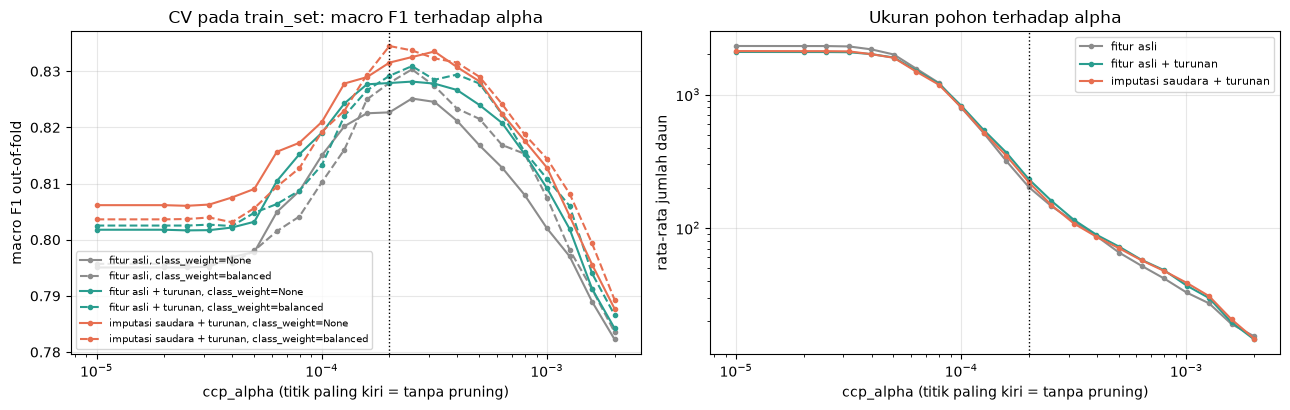

In [27]:
# Kurva CV: macro F1 terbaik per alpha (threshold disetel) dan rata-rata jumlah daun.
fig, (ax_f1, ax_leaves) = plt.subplots(1, 2, figsize=(13, 4.2))
colors = dict(zip(DTL_VARIANTS, ['#8c8c8c', '#2a9d8f', '#e76f51']))
plot_alphas = np.where(DTL_ALPHAS == 0, DTL_ALPHAS[1] / 2, DTL_ALPHAS)
for (variant, class_weight), group in dtl_search.groupby(['variant', 'class_weight'], sort=False):
    curve = group.groupby('alpha')['oof_macro_f1'].max().reindex(DTL_ALPHAS)
    style = '-' if class_weight == 'None' else '--'
    ax_f1.plot(plot_alphas, curve, style, color=colors[variant], marker='o', markersize=3,
               label=f'{variant}, class_weight={class_weight}')
    if class_weight == 'None':
        leaves = group.groupby('alpha')['leaves'].first().reindex(DTL_ALPHAS)
        ax_leaves.plot(plot_alphas, leaves, color=colors[variant], marker='o', markersize=3, label=variant)
for ax in (ax_f1, ax_leaves):
    ax.set_xscale('log')
    ax.axvline(DTL_PARAMS['ccp_alpha'], color='black', linestyle=':', linewidth=1)
    ax.set_xlabel('ccp_alpha (titik paling kiri = tanpa pruning)')
    ax.grid(alpha=.3)
ax_f1.set_ylabel('macro F1 out-of-fold')
ax_f1.set_title('CV pada train_set: macro F1 terhadap alpha')
ax_f1.legend(fontsize=7.5, loc='lower left')
ax_leaves.set_yscale('log')
ax_leaves.set_ylabel('rata-rata jumlah daun')
ax_leaves.set_title('Ukuran pohon terhadap alpha')
ax_leaves.legend(fontsize=8)
fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'dtl_ccp_cv.png', dpi=150, bbox_inches='tight')
plt.show()

Tanpa pruning, pohon mencapai sekitar 2.100–2.300 daun dengan macro F1 out-of-fold hanya 0,795–0,806. Kurva macro F1 terhadap $\alpha$ berbentuk ∩, sesuai trade-off bias–variance. Pada $\alpha$ kecil pohon *overfit* karena daunnya hanya cocok untuk kasus-kasus individual. Pada $\alpha > 10^{-3}$ pohon terlalu sederhana (kurang dari 40 daun) sehingga skornya turun tajam. Puncaknya ada di $\alpha \approx 2$–$4 \cdot 10^{-4}$, yaitu 100–190 daun. Pada titik ini pruning saja menaikkan macro F1 OOF sekitar 0,027 untuk ketiga varian fitur, sambil memangkas lebih dari 90% daun.

Fitur turunan dan imputasi pemesanan serupa menggeser seluruh kurva ke atas. Dengan $\alpha$ terbaik dan threshold 0,5, macro F1 OOF naik dari 0,8245 (fitur asli) menjadi 0,8281 (+ fitur turunan) dan 0,8333 (+ imputasi pemesanan serupa). `class_weight='balanced'` dengan threshold 0,5 justru lebih buruk (0,8232), karena bobot kelas batal yang lebih besar membuat pohon terlalu sering memprediksi batal. Setelah threshold digeser ke 0,72, skornya menjadi yang tertinggi (0,8345). Peluang berbobot 0,72 setara dengan peluang batal asli sekitar 0,55, sehingga keputusan akhirnya tetap dekat aturan mayoritas. Selisihnya terhadap varian tanpa bobot (0,8335) hanya 0,0010, jadi keduanya praktis setara. Kami tetap memakai konfigurasi dengan skor OOF tertinggi agar pemilihan sepenuhnya mengikuti prosedur CV.

### Penyetelan Preprocessing dan Training Decision Tree Learning

Konfigurasi terbaik dari CV dilatih ulang pada seluruh `train_set` dan menggantikan hasil perbandingan awal. Tabel berikut menunjukkan pengaruh setiap langkah pada `val_set`, mulai dari pohon awal sampai konfigurasi akhir.

In [28]:
# Konfigurasi terbaik dari CV dilatih ulang pada seluruh train_set; setiap langkah dibandingkan pada val_set.
def tree_matrix_for_sklearn(fit_frame, frame):
    # One-hot kategori untuk scikit-learn; nilai kosong tetap NaN karena DecisionTreeClassifier
    # mendukung missing value secara bawaan.
    parts = [frame.drop(columns=CATEGORICAL_COLUMNS).astype(float)]
    for column in CATEGORICAL_COLUMNS:
        levels = sorted(fit_frame[column].dropna().unique())
        onehot = pd.DataFrame({f'{column}={level}': (frame[column] == level).astype(float)
                               for level in levels}, index=frame.index)
        onehot[frame[column].isna()] = np.nan
        parts.append(onehot)
    return pd.concat(parts, axis=1).to_numpy()


def best_alpha(variant, class_weight='None'):
    rows = dtl_search[(dtl_search['variant'] == variant) & (dtl_search['class_weight'] == class_weight)
                      & (dtl_search['threshold'] == .5)]
    return float(best_dtl_row(rows)['alpha'])


raw_prep = make_tree_preprocessor(derived=False, sibling_imputation=False).fit(train_set)
dtl_prep = make_tree_preprocessor(**DTL_PREP_KWARGS).fit(train_set)
X_train_tree, X_val_tree = dtl_prep.transform(train_set), dtl_prep.transform(val_set)
X_train_tree_sk = tree_matrix_for_sklearn(X_train_tree, X_train_tree)
X_val_tree_sk = tree_matrix_for_sklearn(X_train_tree, X_val_tree)

dtl_steps = [
    ('1. Awal: 5.000 baris, depth 10, leaf 20', None, None),
    ('2. Seluruh train_set, depth 10, leaf 20', raw_prep, dict(max_depth=10, min_samples_leaf=20)),
    ('3. Pohon penuh tanpa pruning', raw_prep, dict()),
    ('4. + cost-complexity pruning', raw_prep, dict(ccp_alpha=best_alpha('fitur asli'))),
    ('5. + fitur turunan & imputasi saudara', dtl_prep,
     dict(ccp_alpha=best_alpha(DTL_BEST['variant']))),
    ('6. + class weight & threshold (final)', dtl_prep, DTL_PARAMS),
]
dtl_ablation, dtl_models = [], {}
for name, prep, params in dtl_steps:
    if prep is None:
        model, predicted = models['CART'], predictions['CART']
        fit_seconds = next(row['fit_seconds'] for row in results if row['model'] == 'CART')
    else:
        X_fit, X_eval = prep.transform(train_set), prep.transform(val_set)
        start = perf_counter()
        model = DecisionTree(**params).fit(X_fit, y_train_array)
        fit_seconds = perf_counter() - start
        predicted = model.predict(X_eval)
    dtl_models[name] = (model, predicted)
    f1_per_class = f1_score(y_valid, predicted, average=None)
    dtl_ablation.append({
        'langkah': name, 'macro_f1': f1_score(y_valid, predicted, average='macro'),
        'accuracy': accuracy_score(y_valid, predicted), 'f1_tidak_batal': f1_per_class[0],
        'f1_batal': f1_per_class[1], 'daun': model.n_leaves_, 'kedalaman': model.depth_,
        'fit_detik': fit_seconds,
    })
dtl_ablation = pd.DataFrame(dtl_ablation)
print('Ablasi DTL pada val_set:')
print(dtl_ablation.round(4).to_string(index=False))

# Model final DTL menggantikan baseline pada perbandingan semua model.
dtl_final, dtl_val_pred = dtl_models[dtl_steps[-1][0]]
models['CART'], predictions['CART'] = dtl_final, dtl_val_pred
model_factories['CART'] = ('tree', lambda: DecisionTree(**DTL_PARAMS))
model_inputs['tree'] = (X_train_tree, X_val_tree, y_train_array)
for row in results:
    if row['model'] == 'CART':
        row.update(macro_f1=dtl_ablation['macro_f1'].iloc[-1], accuracy=dtl_ablation['accuracy'].iloc[-1],
                   fit_seconds=dtl_ablation['fit_detik'].iloc[-1])

Ablasi DTL pada val_set:
                                langkah  macro_f1  accuracy  f1_tidak_batal  f1_batal  daun  kedalaman  fit_detik
1. Awal: 5.000 baris, depth 10, leaf 20    0.7684    0.8078          0.8639    0.6729   139         10     1.1550
2. Seluruh train_set, depth 10, leaf 20    0.8181    0.8436          0.8862    0.7500   247         10     1.1162
           3. Pohon penuh tanpa pruning    0.8061    0.8279          0.8711    0.7411  2877         32     5.7610
           4. + cost-complexity pruning    0.8272    0.8506          0.8908    0.7636   101         13     4.2151
  5. + fitur turunan & imputasi saudara    0.8290    0.8544          0.8949    0.7632   101         13     7.9432
  6. + class weight & threshold (final)    0.8389    0.8595          0.8965    0.7813   203         15    12.9245


Pada `val_set`, macro F1 DTL naik dari 0,7684 menjadi 0,8389 (+0,071). Kontribusi setiap langkahnya adalah sebagai berikut.

- Memakai seluruh `train_set` menambah 0,050. Skor awal rendah terutama karena model hanya dilatih pada 5.000 baris. Dengan parameter yang sama, seluruh `train_set` menaikkan F1 kelas batal dari 0,673 ke 0,750.
- Pohon penuh tanpa pruning turun 0,012 dari langkah 2. Tanpa batas, pohon mencapai 2.877 daun dengan kedalaman 32. Akurasi training-nya sempurna, tetapi macro F1 validasi turun ke 0,8061. Ini bukti *overfitting* yang ditangani pruning.
- Cost-complexity pruning menambah 0,021 dari pohon penuh. Pohon dipangkas menjadi 101 daun dan kedalaman 13. Hasilnya (0,8272) lebih baik daripada `max_depth=10, min_samples_leaf=20` yang dipilih manual (0,8181), karena pruning memangkas berdasarkan manfaat setiap subpohon, bukan memotong rata di kedalaman tertentu.
- Fitur turunan dan imputasi pemesanan serupa hanya menambah 0,002. Di CV, langkah ini memberi +0,009, sedangkan di validasi hanya +0,002. Selisih sekecil ini masih berada dalam variasi acak satu split validasi berisi 5.474 baris, sehingga hasil CV pada lima fold lebih bisa diandalkan.
- Class weight dan threshold menambah 0,010. Langkah ini paling memperbaiki kelas minoritas: F1 batal naik dari 0,763 ke 0,781, recall batal 0,766, dan precision batal 0,797.

Seluruh konfigurasi dipilih dengan CV pada `train_set`, sehingga skor validasi 0,8389 tidak bias oleh pemilihan hyperparameter.

### Visualisasi Pohon (Bonus)

`plot_decision_tree(model, top_n=N)` menggambar N percabangan terpenting. Percabangan dipilih secara *best-first* dari akar berdasarkan penurunan Gini berbobot, sehingga yang tampil selalu terhubung ke akar dan paling berpengaruh. Subpohon di luar N split teratas diringkas menjadi kotak putus-putus. Warna kotak menunjukkan proporsi pemesanan batal, tebal panah menunjukkan jumlah data, dan label `NaN` menunjukkan arah nilai kosong.

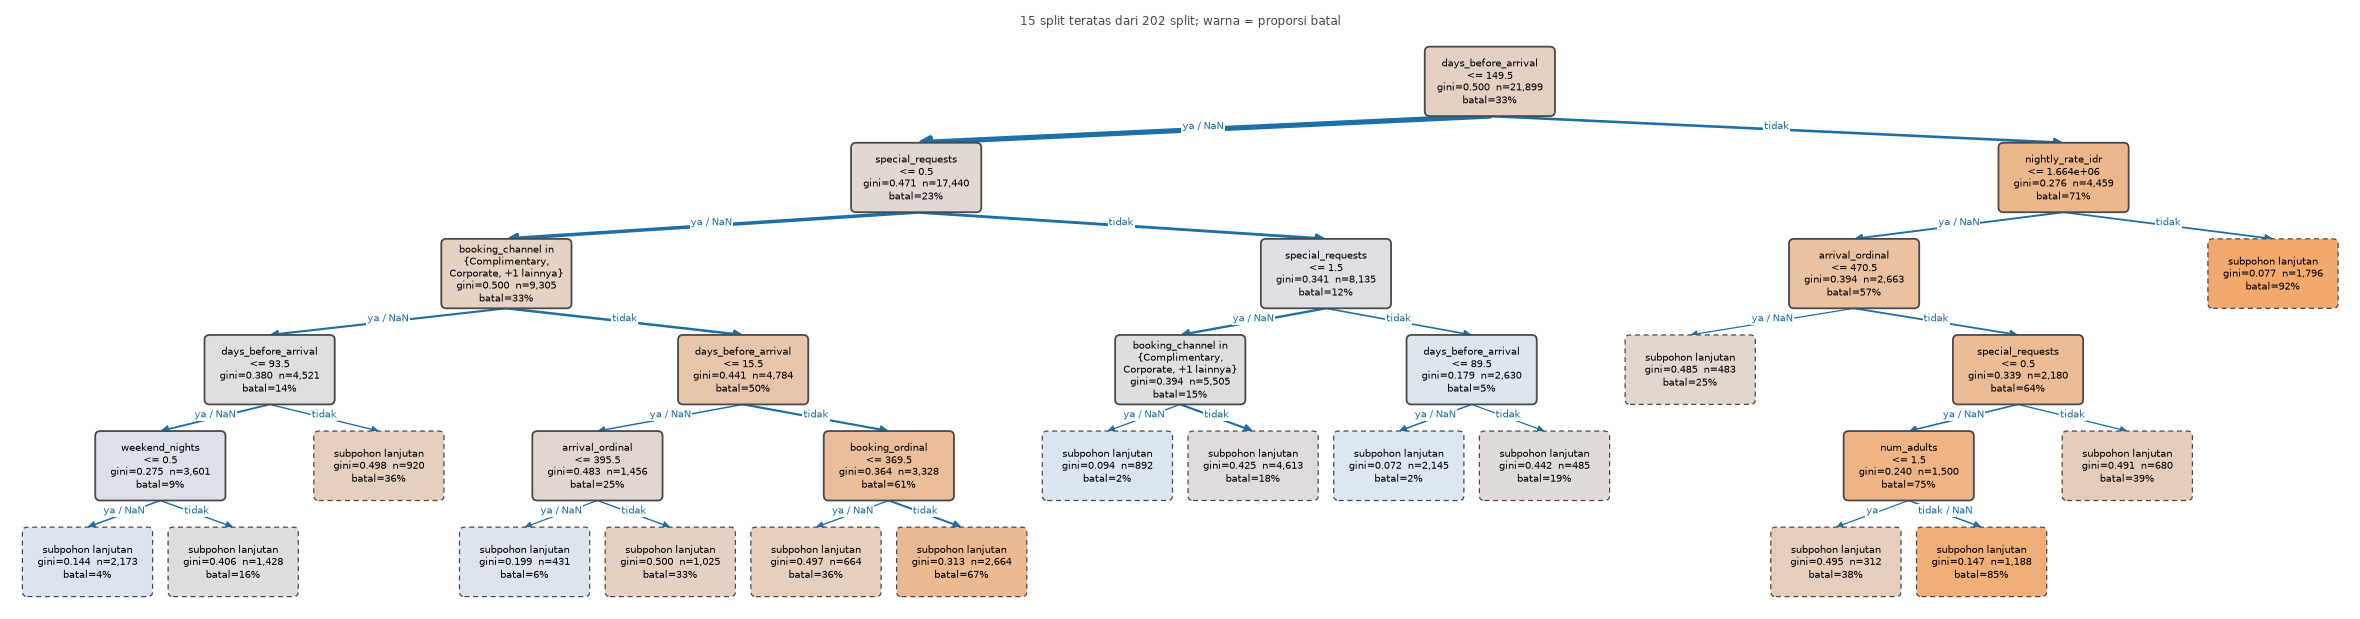

Pohon final: 203 daun, kedalaman 15, dari pohon penuh 2596 daun


In [29]:
DTL_TOP_N = 15
ax = plot_decision_tree(dtl_final, top_n=DTL_TOP_N)
ax.figure.savefig(CFG.OUTPUT_DIR / f'dtl_tree_top{DTL_TOP_N}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Pohon final: {dtl_final.n_leaves_} daun, kedalaman {dtl_final.depth_}, '
      f'dari pohon penuh {dtl_final.full_tree_n_leaves_} daun')

Split pertama pada pohon memisahkan pemesanan dengan lead time di atas 149,5 hari. Di cabang ini 71% pemesanan batal, dan jika harga per malam juga tinggi (> Rp1,66 juta) proporsinya naik menjadi 92%. Pemesanan dengan lead time lebih pendek dipecah oleh `special_requests`. Tamu yang mengajukan permintaan khusus jarang membatalkan (12%, dan hanya 5% jika permintaannya lebih dari satu). Tanpa permintaan khusus, pemesanan lewat kanal `Complimentary`, `Corporate`, atau `Offline Agent` jauh lebih jarang batal (14%) dibanding `Online Travel Agent` dan `Airline` (50%). Nilai kosong pada `days_before_arrival` dan `special_requests` mengikuti cabang kiri, yaitu cabang lead time pendek dan cabang tanpa permintaan khusus. Pohon mempelajari arah ini langsung dari data, tanpa imputasi.

Nilai Gini pada gambar dihitung dengan bobot kelas (`class_weight='balanced'`), sehingga Gini akar 0,5. Persentase batal menunjukkan proporsi asli di data training.

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [30]:
for name in ('LogReg L1', 'LogReg L2', 'LogReg Elastic Net'):
    evaluate(name)
logreg_ablation_base = [dict(row) for row in results if row['model'].startswith('LogReg')]

LogReg L1 {'macro_f1': 0.745, 'accuracy': 0.7939, 'fit_seconds': 0.0662, 'predict_seconds': 0.0011}
LogReg L2 {'macro_f1': 0.7458, 'accuracy': 0.793, 'fit_seconds': 0.0255, 'predict_seconds': 0.0003}
LogReg Elastic Net {'macro_f1': 0.7445, 'accuracy': 0.7928, 'fit_seconds': 0.0323, 'predict_seconds': 0.0003}


Ketiga bentuk regularisasi dilatih pada matriks numerik yang sama. Perbandingan ini menunjukkan pengaruh L1, L2, dan Elastic Net pada data validasi.

### Optimasi Logistic Regression: FISTA

Di kelas, bobot Logistic Regression diperbarui dengan *gradient descent* atau *stochastic gradient ascent* dengan *learning rate* tetap. Implementasi kami memakai FISTA (*Fast Iterative Shrinkage-Thresholding Algorithm*) karena dua alasan: regularisasi L1 tidak dapat diturunkan di titik nol, dan *gradient descent* biasa lambat ketika fitur saling berkorelasi.

Fungsi objektifnya adalah rata-rata *log-loss* ditambah penalti, $F(w, b) = f(w, b) + \lambda\rho\lVert w\rVert_1$, dengan $f$ berisi *log-loss* dan bagian L2 yang dapat diturunkan. Setiap iterasi terdiri atas empat langkah:

1. Langkah gradien pada bagian yang dapat diturunkan: $v = y_k - t\,\nabla f(y_k)$.
2. Operator proximal untuk L1, yaitu *soft-thresholding*: $w_{k+1} = \operatorname{sign}(v)\max(|v| - t\lambda\rho, 0)$. Bobot yang kecil langsung menjadi nol, sehingga L1 dan Elastic Net menghasilkan model yang jarang (*sparse*).
3. Momentum Nesterov: titik berikutnya diekstrapolasi, $y_{k+1} = w_{k+1} + \frac{m_k - 1}{m_{k+1}}(w_{k+1} - w_k)$ dengan $m_{k+1} = \frac{1 + \sqrt{1 + 4m_k^2}}{2}$. Momentum ini menaikkan laju konvergensi dari $O(1/k)$ menjadi $O(1/k^2)$ (Beck & Teboulle, 2009).
4. Backtracking memilih ukuran langkah $t$ secara otomatis, sehingga tidak perlu menyetel *learning rate*. Jika nilai objektif naik, momentum di-*restart* agar iterasi tidak berosilasi (O'Donoghue & Candès, 2015).

Sel berikut membandingkan FISTA dengan *proximal gradient* tanpa momentum (`accelerate=False`) pada data dan regularisasi yang sama.

             model        optimizer  iterations  seconds  objective
         LogReg L1            FISTA          58 0.079675   0.476716
         LogReg L1 tanpa akselerasi         330 0.338420   0.476716
         LogReg L2            FISTA          41 0.027501   0.446893
         LogReg L2 tanpa akselerasi         181 0.131343   0.446893
LogReg Elastic Net            FISTA          35 0.026372   0.463485
LogReg Elastic Net tanpa akselerasi         193 0.111813   0.463485


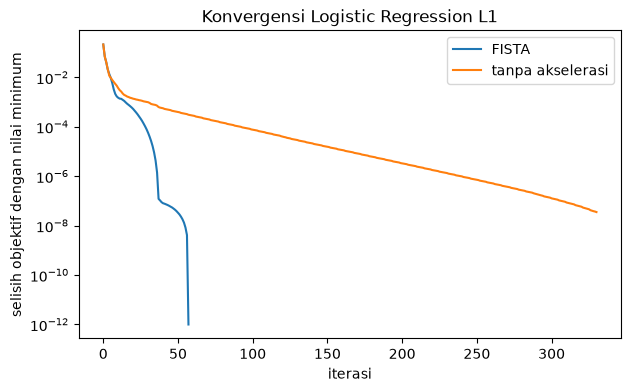

In [31]:
X_fit_numeric, _, y_fit_numeric = model_inputs['numeric']
fista_rows, loss_curves = [], {}
for name, params in logreg_params.items():
    for label, accelerate in (('FISTA', True), ('tanpa akselerasi', False)):
        start = perf_counter()
        model = LogisticRegression(**{**params, 'max_iter': 10_000}, accelerate=accelerate).fit(X_fit_numeric, y_fit_numeric)
        fista_rows.append({'model': name, 'optimizer': label, 'iterations': model.n_iter_,
                           'seconds': perf_counter() - start, 'objective': model.loss_history_[-1]})
        if name == 'LogReg L1':
            loss_curves[label] = np.array(model.loss_history_)
print(pd.DataFrame(fista_rows).round(6).to_string(index=False))

best_objective = min(curve.min() for curve in loss_curves.values())
fig, ax = plt.subplots(figsize=(7, 4))
for label, curve in loss_curves.items():
    ax.semilogy(curve - best_objective + 1e-12, label=label)
ax.set_xlabel('iterasi')
ax.set_ylabel('selisih objektif dengan nilai minimum')
ax.set_title('Konvergensi Logistic Regression L1')
ax.legend()
plt.show()

FISTA mencapai nilai objektif yang sama persis dengan *proximal gradient* biasa, tetapi dengan iterasi 4,4–5,7 kali lebih sedikit: 58 vs 330 iterasi untuk L1, 41 vs 181 untuk L2, dan 35 vs 193 untuk Elastic Net. Karena titik akhirnya sama, perbedaan keduanya hanya pada kecepatan mencapai minimum, bukan pada kualitas model. Grafik konvergensi L1 menunjukkan selisih objektif FISTA turun jauh lebih curam sejak iterasi awal.

### Penyetelan Preprocessing dan Training Logistic Regression

Perbandingan awal memakai lima ribu baris, pipeline `numeric`, kekuatan regularisasi tetap, dan threshold 0,5. Ketiganya membatasi model linear:

- Logistic Regression cepat dilatih, sehingga seluruh `train_set` dapat dipakai.
- Pipeline `linear` dipakai karena pengaruh `days_before_arrival` dan musim terhadap pembatalan tidak lurus. Lead time diberi transformasi log dan juga dipotong menjadi bin kuantil, sedangkan bulan, hari, dan tahun kedatangan di-one-hot. Fitur yang miring diberi log, dan nilai kosong diberi penanda sebelum diimputasi.
- Jumlah bin lead time (0 atau 10), kekuatan regularisasi, dan threshold dipilih dari prediksi out-of-fold 5-fold CV pada `train_set`. `val_set` tidak dipakai untuk memilih.

In [32]:
LOGREG_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
LOGREG_LEAD_BINS = (0, 10)
LOGREG_STRENGTHS = (1e-4, 1e-3, 1e-2)
y_train_array = y_train.to_numpy()

logreg_folds = {}
for lead_bins in LOGREG_LEAD_BINS:
    logreg_folds[lead_bins] = []
    for fit_rows, eval_rows in LOGREG_CV.split(train_set, y_train_array):
        fold_prep = make_linear_preprocessor(lead_bins).fit(train_set.iloc[fit_rows])
        logreg_folds[lead_bins].append((fit_rows, eval_rows, fold_prep.transform(train_set.iloc[fit_rows]),
                                        fold_prep.transform(train_set.iloc[eval_rows])))

logreg_search = []
for name, params in logreg_params.items():
    for lead_bins in LOGREG_LEAD_BINS:
        for strength in LOGREG_STRENGTHS:
            oof = np.zeros(len(train_set))
            for fit_rows, eval_rows, X_fold_fit, X_fold_eval in logreg_folds[lead_bins]:
                fold_model = LogisticRegression(**{**params, 'reg_strength': strength, 'max_iter': 5000})
                oof[eval_rows] = fold_model.fit(X_fold_fit, y_train_array[fit_rows]).predict_proba(X_fold_eval)[:, 1]
            threshold, score = best_threshold(y_train_array, oof)
            logreg_search.append({'model': name, 'lead_bins': lead_bins, 'reg_strength': strength,
                                  'threshold': threshold, 'cv_macro_f1': score})
logreg_search = pd.DataFrame(logreg_search)
LOGREG_LEAD_BINS_BEST = int(logreg_search.groupby('lead_bins')['cv_macro_f1'].max().idxmax())
logreg_best = (logreg_search[logreg_search['lead_bins'] == LOGREG_LEAD_BINS_BEST]
               .sort_values('cv_macro_f1', ascending=False).groupby('model').head(1).set_index('model'))
print('Hasil CV terbaik per regularisasi:')
print(logreg_search.sort_values('cv_macro_f1', ascending=False).groupby('model').head(2).round(4).to_string(index=False))

linear_prep = make_linear_preprocessor(LOGREG_LEAD_BINS_BEST).fit(train_set)
X_train_linear, X_val_linear = linear_prep.transform(train_set), linear_prep.transform(val_set)
logreg_ablation = []
for name in logreg_params:
    tuned = {**logreg_params[name], 'reg_strength': float(logreg_best.loc[name, 'reg_strength']),
             'max_iter': 5000}
    plain = LogisticRegression(**tuned).fit(X_train_linear, y_train_array)
    start = perf_counter()
    final = LogisticRegression(**tuned, threshold=float(logreg_best.loc[name, 'threshold']))
    final.fit(X_train_linear, y_train_array)
    fit_seconds = perf_counter() - start
    logreg_params[name] = {**tuned, 'threshold': final.threshold}
    predicted = replace_result(name, 'linear', lambda params=logreg_params[name]: LogisticRegression(**params),
                               final, X_train_linear, X_val_linear, y_train_array, fit_seconds)
    baseline = next(row for row in logreg_ablation_base if row['model'] == name)['macro_f1']
    logreg_ablation.append({
        'model': name, 'awal (5.000 baris, numeric)': baseline,
        'train_set + linear (t=0,5)': f1_score(y_valid, plain.predict(X_val_linear), average='macro'),
        '+ threshold CV (final)': f1_score(y_valid, predicted, average='macro'),
        'reg_strength': final.reg_strength, 'threshold': final.threshold,
    })
print(f'Bin lead time terpilih: {LOGREG_LEAD_BINS_BEST}')
print(pd.DataFrame(logreg_ablation).round(4).to_string(index=False))

Hasil CV terbaik per regularisasi:
             model  lead_bins  reg_strength  threshold  cv_macro_f1
         LogReg L1         10        0.0010       0.42       0.7854
LogReg Elastic Net         10        0.0010       0.41       0.7839
         LogReg L2         10        0.0001       0.42       0.7836
LogReg Elastic Net         10        0.0001       0.42       0.7832
         LogReg L1         10        0.0001       0.40       0.7832
         LogReg L2         10        0.0010       0.42       0.7828


Bin lead time terpilih: 10
             model  awal (5.000 baris, numeric)  train_set + linear (t=0,5)  + threshold CV (final)  reg_strength  threshold
         LogReg L1                       0.7450                      0.7771                  0.7904        0.0010       0.42
         LogReg L2                       0.7458                      0.7798                  0.7887        0.0001       0.42
LogReg Elastic Net                       0.7445                      0.7779                  0.7892        0.0010       0.41


Macro F1 validasi ketiga regularisasi naik dari sekitar 0,745 menjadi 0,789–0,790. Kenaikan terbesar (sekitar +0,03) datang dari seluruh `train_set` dan pipeline `linear`, lalu threshold hasil CV menambah sekitar +0,01. CV memilih 10 bin lead time untuk ketiga regularisasi, yang menegaskan bahwa pengaruh `days_before_arrival` terhadap pembatalan memang tidak linear. Threshold terpilih 0,41–0,42 berada di bawah 0,5 karena macro F1 memberi bobot sama pada kelas batal yang lebih sedikit.

L1, L2, dan Elastic Net menghasilkan skor yang hampir sama, dan kekuatan regularisasi terbaik kecil (0,0001–0,001). Dengan sekitar 22 ribu baris dan 68 kolom, model linear ini jauh dari *overfitting*, sehingga regularisasi tidak banyak mengubah hasil. Batasnya ada pada bentuk modelnya: Logistic Regression tetap tidak dapat memanfaatkan kemiripan antarpemesanan serupa seperti KNN.

In [33]:
logreg_lead_time = train_set['days_before_arrival']
logreg_lead_time = logreg_lead_time.fillna(logreg_lead_time.median()).to_numpy(dtype=float)
x_logreg_bonus = (logreg_lead_time - logreg_lead_time.mean()) / logreg_lead_time.std()
y_logreg_bonus = train_set['is_canceled'].to_numpy()

logreg_bonus = LogisticRegression(reg_strength=0.0, class_weight=None)
logreg_bonus.fit(x_logreg_bonus[:, None], y_logreg_bonus)
logreg_video_path = CFG.OUTPUT_DIR / 'logistic_regression_optimization.mp4'
save_logistic_regression_animation(
    x_logreg_bonus, y_logreg_bonus,
    logreg_bonus.parameter_history_, logreg_bonus.loss_history_, logreg_video_path,
)
display(Video(filename=str(logreg_video_path), embed=True))

<!-- rubric v3: total slack, slack_total -->

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [34]:
for name in ('SVM Linear', 'SVM Polynomial', 'SVM Gaussian'):
    evaluate(name)

SVM Linear {'macro_f1': 0.7588, 'accuracy': 0.7994, 'fit_seconds': 14.7646, 'predict_seconds': 0.0797}


SVM Polynomial {'macro_f1': 0.7916, 'accuracy': 0.8202, 'fit_seconds': 15.3555, 'predict_seconds': 0.4316}


SVM Gaussian {'macro_f1': 0.8114, 'accuracy': 0.8356, 'fit_seconds': 4.8253, 'predict_seconds': 0.5134}


Kernel linear, polinomial, dan Gaussian diuji pada sampel training yang sama. Hasil validasi menunjukkan apakah batas keputusan nonlinier membantu klasifikasi pemesanan.

### Optimasi SVM: SMO dengan Working Set Selection Orde Dua

Di kelas, SVM dilatih dengan menyelesaikan bentuk dual Lagrangian sebagai *quadratic programming* (QP). QP umum membutuhkan matriks kernel $n \times n$ secara utuh, yaitu sekitar 3,8 GB untuk 21.899 baris training, sehingga tidak praktis untuk data ini. Implementasi kami memakai **Sequential Minimal Optimization** (SMO, Platt, 1998):

1. Setiap iterasi hanya mengubah dua koefisien dual $\alpha_i$ dan $\alpha_j$. Karena batasan $\sum_k y_k\alpha_k = 0$ harus tetap terpenuhi, subproblem dua variabel ini punya solusi analitik, sehingga tidak perlu solver QP.
2. Gradien dual diperbarui dengan dua baris kernel saja. Baris kernel yang sering dipakai disimpan dalam *cache* LRU, jadi matriks kernel penuh tidak pernah dibentuk.
3. Training berhenti ketika pelanggaran kondisi KKT terbesar di bawah toleransi (`tol`).

Kunci kecepatan SMO ada pada pemilihan pasangan $(i, j)$. Indeks $i$ adalah pelanggar KKT terbesar. Untuk $j$, SMO klasik memilih pelanggar terbesar di sisi lain (*maximal violating pair*, Keerthi dkk., 2001). Kami memakai **pemilihan orde dua** (Fan, Chen, & Lin, 2005), yang memilih $j$ dengan penurunan objektif dual terbesar:

$$j = \arg\min_t \; -\frac{b_{it}^2}{a_{it}}, \qquad a_{it} = K_{ii} + K_{tt} - 2K_{it},\quad b_{it} = -y_i\nabla_i + y_t\nabla_t.$$

Rumus ini memakai kelengkungan objektif ($a_{it}$), bukan hanya gradien, sehingga setiap langkah lebih efektif dan jumlah iterasi berkurang. Sel berikut membandingkan kedua cara pemilihan pada SVM Gaussian.

In [35]:
X_fit_svm, X_eval_svm, y_fit_svm = model_inputs['svm']
smo_rows, smo_predictions = [], {}
for selection in ('second_order', 'first_order'):
    start = perf_counter()
    model = SVM(kernel='gaussian', selection=selection, **svm_params['gaussian']).fit(X_fit_svm, y_fit_svm)
    smo_predictions[selection] = model.predict(X_eval_svm)
    smo_rows.append({'selection': selection, 'iterations': model.n_iter_, 'seconds': perf_counter() - start,
                     'support_vectors': len(model.support_),
                     'macro_f1': f1_score(y_valid, smo_predictions[selection], average='macro')})
print(pd.DataFrame(smo_rows).round(4).to_string(index=False))
print('Kesamaan prediksi kedua cara:', np.mean(smo_predictions['second_order'] == smo_predictions['first_order']))

   selection  iterations  seconds  support_vectors  macro_f1
second_order        9454   7.7466             2530    0.8114
 first_order       18054   5.7827             2531    0.8114
Kesamaan prediksi kedua cara: 1.0


Kedua cara pemilihan menghasilkan model yang sama: jumlah *support vector* hampir identik (2.530 dan 2.531), macro F1 sama (0,8114), dan prediksi validasi 100% sama. Pemilihan orde dua hanya butuh 9.454 iterasi, hampir setengah dari 18.054 iterasi pada pemilihan orde satu. Waktu training tidak ikut turun setengah (7,7 detik untuk orde dua vs 5,8 detik untuk orde satu pada run ini) karena setiap iterasi orde dua menghitung kelengkungan untuk semua kandidat $j$, dan waktunya juga bergantung pada mesin.

### Visualisasi Kernel SVM (Bonus)

Data SVM memiliki banyak dimensi, sehingga diproyeksikan ke dua komponen utama (PCA) terlebih dahulu. Dari proyeksi tersebut diambil 500 pemesanan dari setiap kelas agar bidang pemisah tidak tertarik ke kelas mayoritas. Satu SVM dilatih untuk setiap kernel dengan C = 1 dan γ bawaan; kernel polynomial memakai derajat 3 dan coef0 = 1. Garis tegas adalah bidang pemisah $f(x) = 0$, garis putus-putus adalah margin $f(x) = \pm 1$, titik yang dilingkari adalah *support vector*, dan warna merah menandai pemesanan yang batal.

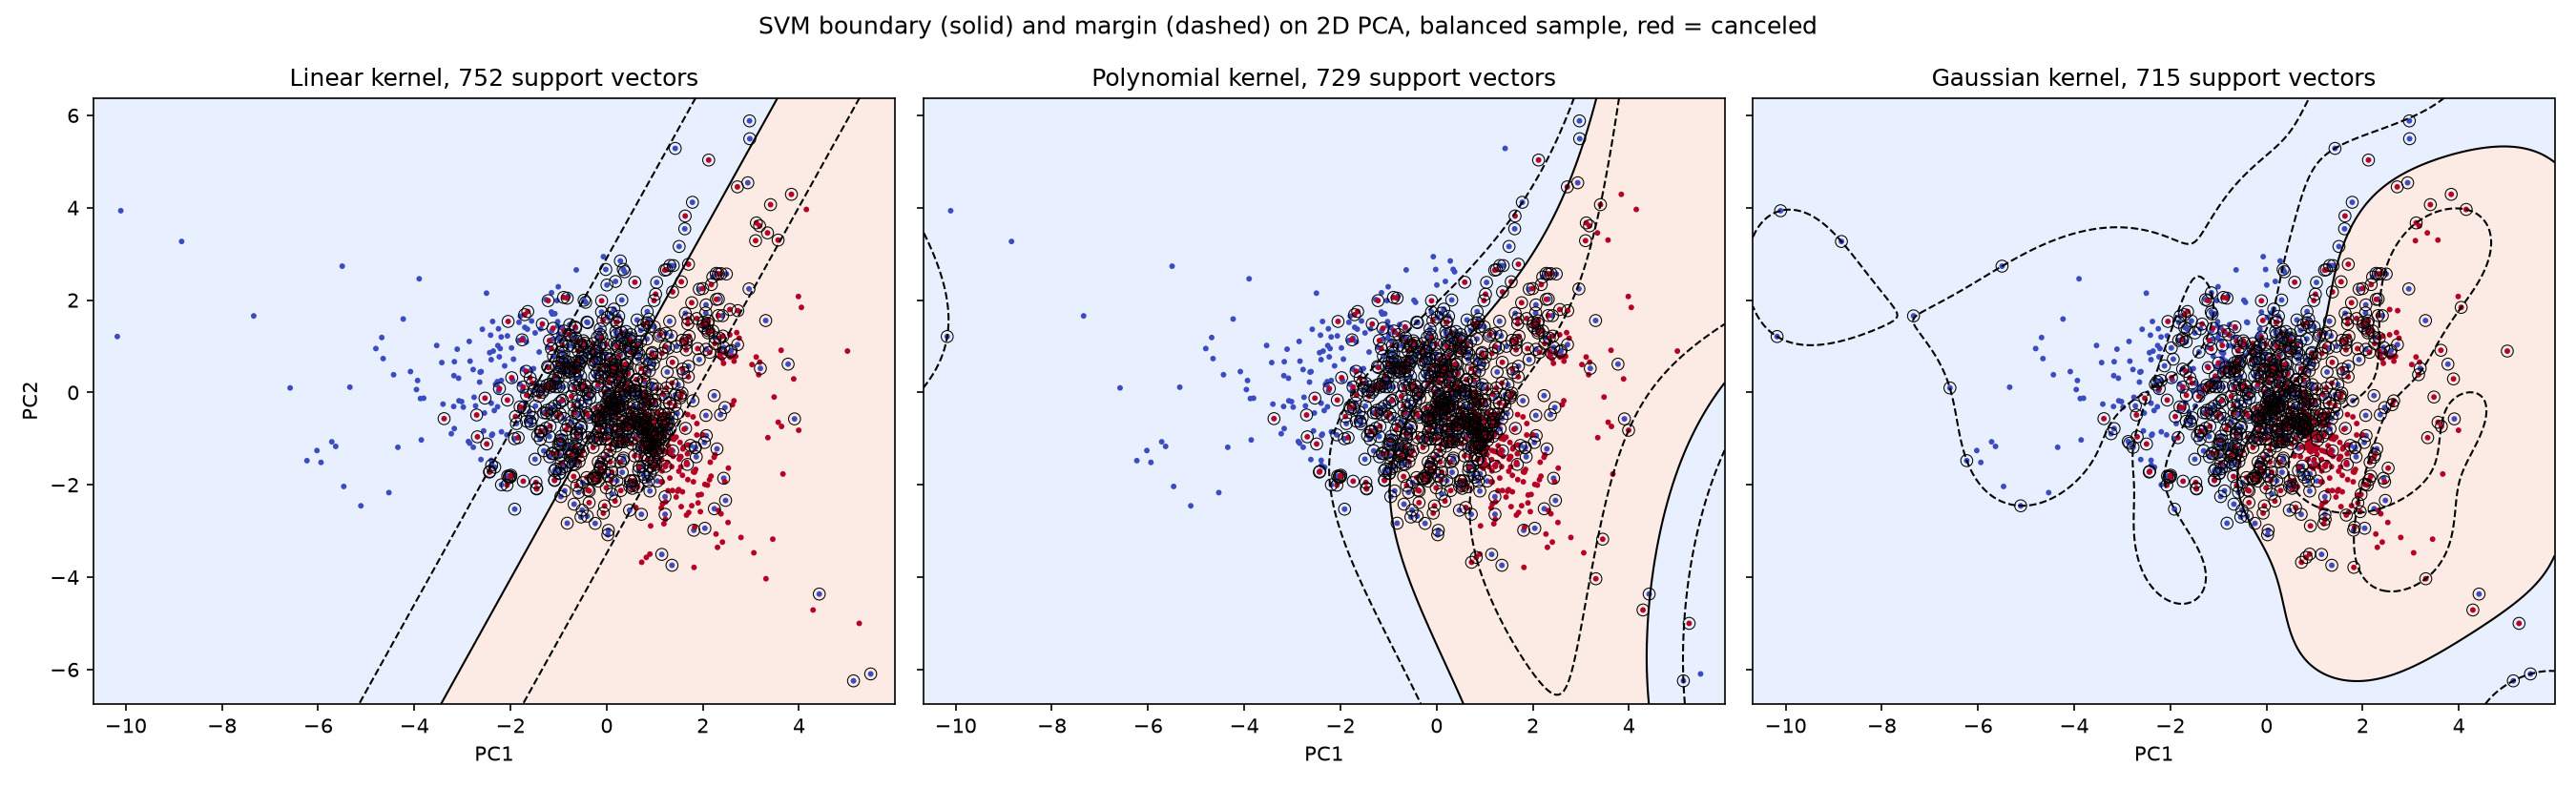

In [36]:
svm_figure_path = CFG.OUTPUT_DIR / 'svm_kernels.png'
plot_kernels(X_train_svm, y_train.to_numpy(), svm_figure_path, seed=CFG.SEED)
display(Image(filename=str(svm_figure_path)))

Kernel linear membentuk bidang pemisah berupa garis lurus, kernel polynomial membentuk batas melengkung, dan kernel Gaussian membentuk daerah tertutup di sekitar kumpulan pemesanan batal (PC1 positif dan PC2 negatif). Sekitar tiga perempat titik pada setiap panel menjadi *support vector* (752, 729, dan 715 dari 1.000 titik), karena kedua kelas bertumpuk di tengah proyeksi dua dimensi ini. Kernel Gaussian memerlukan *support vector* paling sedikit karena batasnya paling fleksibel, sejalan dengan macro F1 validasinya yang tertinggi di antara ketiga kernel. Pemisahan pada model sebenarnya lebih baik daripada yang terlihat di sini, karena model memakai seluruh 43 dimensi, bukan hanya dua komponen utama.

### Penyetelan Training SVM

SVM tetap memakai pipeline `svm`, tetapi hyperparameter-nya disetel dan data training-nya diperbesar:

- C (dan γ untuk kernel polynomial serta Gaussian) dipilih lewat 3-fold CV pada lima ribu baris perbandingan. Satu kali training SMO pada seluruh `train_set` memakan hampir dua menit, sehingga pencarian grid pada seluruh data tidak praktis.
- Untuk kernel linear dan polynomial yang tetap dilatih pada lima ribu baris, threshold nilai keputusan dipilih dari prediksi out-of-fold CV yang sama.
- Kernel Gaussian memberi hasil terbaik, sehingga konfigurasinya dilatih ulang pada seluruh `train_set`. Nilai keputusan model ini memiliki skala yang berbeda dari model lima ribu baris, sehingga threshold-nya tetap 0 dan keseimbangan kelas diatur oleh `class_weight`.

In [37]:
SVM_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=CFG.SEED)
SVM_GRIDS = {
    'linear': [dict(C=C) for C in (.1, 1)],
    'polynomial': [dict(C=C, degree=3, gamma=gamma, coef0=1) for C in (.3, 1) for gamma in (.03, .1)],
    'gaussian': [dict(C=C, gamma=gamma, class_weight={1: 1.3}) for C in (1, 3, 10) for gamma in (.03, .1)],
}
X_svm_model, _, y_svm_model = model_inputs['svm']
svm_search = []
for kernel, grid in SVM_GRIDS.items():
    for params in grid:
        oof = np.zeros(len(y_svm_model))
        for fit_rows, eval_rows in SVM_CV.split(X_svm_model, y_svm_model):
            fold_model = SVM(kernel=kernel, max_iter=200_000, **params)
            oof[eval_rows] = fold_model.fit(X_svm_model[fit_rows], y_svm_model[fit_rows]).decision_function(
                X_svm_model[eval_rows])
        candidates = np.quantile(oof, np.linspace(.45, .85, 81))
        threshold, score = best_threshold(y_svm_model, oof, candidates)
        score_at_zero = f1_score(y_svm_model, (oof > 0).astype(int), average='macro')
        svm_search.append({'kernel': kernel, 'params': params, 'cv_macro_f1': score, 'threshold': threshold,
                           'cv_macro_f1_threshold_0': score_at_zero})
svm_search = pd.DataFrame(svm_search)
print(svm_search.sort_values('cv_macro_f1', ascending=False).groupby('kernel').head(2)
      .assign(params=lambda frame: frame['params'].astype(str)).round(4).to_string(index=False))

svm_ablation = []
for kernel in SVM_GRIDS:
    rows = svm_search[svm_search['kernel'] == kernel]
    name = f'SVM {kernel.capitalize()}'
    baseline = next(row for row in results if row['model'] == name)['macro_f1']
    if kernel == 'gaussian':
        best = rows.loc[rows['cv_macro_f1_threshold_0'].idxmax()]
        params = {**best['params'], 'max_iter': 1_000_000}
        X_fit, y_fit, kind, note = X_train_svm, y_train_array, 'svm_full', 'train_set penuh, threshold 0'
    else:
        best = rows.loc[rows['cv_macro_f1'].idxmax()]
        params = {**best['params'], 'max_iter': 200_000, 'threshold': float(best['threshold'])}
        X_fit, y_fit, kind, note = X_svm_model, y_svm_model, f'svm_{kernel}', '5.000 baris, threshold CV'
    svm_params[kernel] = params
    start = perf_counter()
    final = SVM(kernel=kernel, **params).fit(X_fit, y_fit)
    fit_seconds = perf_counter() - start
    predicted = replace_result(name, kind, lambda kernel=kernel, params=params: SVM(kernel=kernel, **params),
                               final, X_fit, X_val_svm, y_fit, fit_seconds)
    svm_ablation.append({'model': name, 'awal': baseline, 'setelah penyetelan': f1_score(y_valid, predicted, average='macro'),
                         'konfigurasi': note, 'parameter': {k: v for k, v in params.items() if k != 'max_iter'},
                         'fit_detik': fit_seconds})
print(pd.DataFrame(svm_ablation).round(4).to_string(index=False))

    kernel                                            params  cv_macro_f1  threshold  cv_macro_f1_threshold_0
  gaussian  {'C': 3, 'gamma': 0.1, 'class_weight': {1: 1.3}}       0.8043    -0.0744                   0.7994
  gaussian  {'C': 1, 'gamma': 0.1, 'class_weight': {1: 1.3}}       0.8028    -0.0207                   0.8014
polynomial {'C': 0.3, 'degree': 3, 'gamma': 0.1, 'coef0': 1}       0.7971    -0.2422                   0.7920
polynomial  {'C': 1, 'degree': 3, 'gamma': 0.03, 'coef0': 1}       0.7917    -0.1505                   0.7850
    linear                                          {'C': 1}       0.7703    -0.2646                   0.7670
    linear                                        {'C': 0.1}       0.7700    -0.2522                   0.7684


         model   awal  setelah penyetelan                  konfigurasi                                                                           parameter  fit_detik
    SVM Linear 0.7588              0.7684    5.000 baris, threshold CV                                          {'C': 1, 'threshold': -0.2646389668447527}    15.7508
SVM Polynomial 0.7916              0.7942    5.000 baris, threshold CV {'C': 0.3, 'degree': 3, 'gamma': 0.1, 'coef0': 1, 'threshold': -0.2421657903412092}     5.2049
  SVM Gaussian 0.8114              0.8216 train_set penuh, threshold 0                                    {'C': 1, 'gamma': 0.1, 'class_weight': {1: 1.3}}    99.5680


Kernel Gaussian naik dari 0,811 menjadi 0,822 setelah dilatih pada seluruh `train_set` dengan C = 1, γ = 0,1, dan bobot kelas 1,3 yang dipilih CV. Penambahan data menjadi faktor utamanya: dengan lebih banyak baris, SVM memiliki lebih banyak *support vector* untuk membentuk batas yang mengikuti pola pemesanan. Harga yang dibayar adalah waktu training, sekitar 100 detik dibanding beberapa detik pada lima ribu baris.

Kernel linear paling terbantu oleh threshold (0,759 menjadi 0,768). Batas linear cenderung meremehkan kelas batal, sehingga menggeser threshold ke nilai keputusan negatif menambah prediksi batal yang benar. Kernel polynomial hanya naik sedikit (0,792 menjadi 0,794), karena C yang lebih kecil dan threshold hanya menghaluskan batas yang sudah terbentuk.

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [38]:
for name in ('Naive Bayes', 'Naive Bayes TAN'):
    evaluate(name)

Naive Bayes {'macro_f1': 0.7371, 'accuracy': 0.7742, 'fit_seconds': 0.0029, 'predict_seconds': 0.0034}
Naive Bayes TAN {'macro_f1': 0.7453, 'accuracy': 0.7868, 'fit_seconds': 0.018, 'predict_seconds': 0.0029}


Naive Bayes menerima kode kategori nonnegatif dari pipeline diskret. Fitur numerik tertentu dibagi ke dalam bin sebelum peluang kelas dihitung. Versi TAN memakai masukan dan smoothing yang sama, tetapi setiap fitur boleh bergantung pada satu fitur lain selain kelas. Dengan lima ribu baris training yang sama, macro F1 validasi naik dari 0,737 menjadi 0,745.

### Optimasi Naive Bayes: Tree-Augmented Naive Bayes

Naive Bayes mengasumsikan semua fitur saling independen jika kelasnya sudah diketahui. Pada data ini asumsi tersebut jelas tidak terpenuhi. `weekday_nights` dan `weekend_nights` sama-sama menggambarkan lama menginap, sedangkan `nightly_rate_idr` bergantung pada `room_category` dan bulan kedatangan. Akibatnya, informasi yang sama terhitung lebih dari sekali dan peluang kelas menjadi terlalu ekstrem.

Tree-Augmented Naive Bayes (TAN) melonggarkan asumsi tersebut. Selain kelas, setiap fitur boleh memiliki satu parent $\pi(i)$, sehingga peluang yang dipakai menjadi $P(x_i \mid x_{\pi(i)}, c)$. Struktur parent dipelajari dari data training dengan langkah berikut:

1. Hitung *conditional mutual information* $I(X_i; X_j \mid C)$ untuk setiap pasangan fitur. Nilai ini mengukur seberapa banyak informasi yang dibagi dua fitur setelah kelasnya diketahui.
2. Bentuk graf lengkap antarfitur dengan bobot $I(X_i; X_j \mid C)$, lalu cari *maximum spanning tree* dengan algoritma Prim.
3. Jadikan fitur dengan *mutual information* terbesar terhadap kelas sebagai akar, lalu arahkan semua sisi menjauhi akar.
4. Hitung tabel peluang $P(x_i \mid x_{\pi(i)}, c)$ dengan Laplace smoothing yang sama seperti Naive Bayes.

Langkah tersebut mengoptimasi struktur model. Friedman dkk. (1997) membuktikan, dengan memperluas hasil Chow dan Liu (1968), bahwa pohon dari langkah 2 memaksimalkan *log-likelihood* data training di antara semua struktur yang setiap fiturnya hanya memiliki kelas dan paling banyak satu fitur lain sebagai parent. Struktur optimal itu didapat tanpa pencarian iteratif, cukup dengan satu kali perhitungan statistik dan satu kali pencarian pohon. Naive Bayes biasa adalah kasus khusus TAN tanpa sisi antarfitur, sehingga keduanya memakai kelas dasar yang sama dan hanya berbeda pada cara mempelajari parent setiap fitur.

In [39]:
# Pipeline diskret di-fit ulang pada setiap fold agar statistik bin hanya berasal dari fold training.
nb_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
y_labels = train_df['is_canceled'].to_numpy()
nb_variants = {'Naive Bayes': NaiveBayes, 'Naive Bayes TAN': TreeAugmentedNaiveBayes}
nb_cv_f1 = {name: [] for name in nb_variants}
nb_cv_log_likelihood = {name: [] for name in nb_variants}
for fit_rows, eval_rows in nb_cv.split(train_df, y_labels):
    fold_prep = make_discrete_preprocessor(n_bins=5).fit(train_df.iloc[fit_rows])
    X_fold_fit = fold_prep.transform(train_df.iloc[fit_rows])
    X_fold_eval = fold_prep.transform(train_df.iloc[eval_rows])
    y_fold_eval = y_labels[eval_rows]
    for name, model_class in nb_variants.items():
        fold_model = model_class(alpha=1).fit(X_fold_fit, y_labels[fit_rows])
        nb_cv_f1[name].append(f1_score(y_fold_eval, fold_model.predict(X_fold_eval), average='macro'))
        log_proba = fold_model.predict_log_proba(X_fold_eval)
        nb_cv_log_likelihood[name].append(log_proba[np.arange(len(eval_rows)), y_fold_eval].mean())

nb_cv_df = pd.DataFrame(nb_cv_f1, index=[f'fold {fold}' for fold in range(1, 6)])
nb_cv_df.loc['mean'] = nb_cv_df.mean()
nb_cv_df.loc['std'] = nb_cv_df.iloc[:5].std(ddof=0)
print('Macro F1 5-fold CV:')
print(nb_cv_df.round(4).to_string())
print('Rata-rata log-likelihood per baris validasi:',
      {name: round(float(np.mean(values)), 4) for name, values in nb_cv_log_likelihood.items()})

Macro F1 5-fold CV:
        Naive Bayes  Naive Bayes TAN
fold 1       0.7504           0.7735
fold 2       0.7541           0.7763
fold 3       0.7489           0.7747
fold 4       0.7409           0.7582
fold 5       0.7441           0.7612
mean         0.7477           0.7688
std          0.0047           0.0075
Rata-rata log-likelihood per baris validasi: {'Naive Bayes': -0.4628, 'Naive Bayes TAN': -0.4253}


TAN lebih baik daripada Naive Bayes biasa pada kelima fold. Rata-rata macro F1 naik dari 0,748 menjadi 0,769, sekitar tiga kali simpangan baku antarfold. Rata-rata log-likelihood per baris validasi juga naik dari −0,463 menjadi −0,425, artinya TAN memberi peluang yang lebih tinggi pada kelas yang benar. Kenaikan ini sesuai dengan tujuan optimasinya, karena struktur TAN dipilih untuk memaksimalkan likelihood. Kenaikan tersebut juga terlihat pada fold validasi yang tidak dipakai saat training, sehingga tambahan sisi antarfitur tidak membuat model *overfit*.

Meski begitu, TAN masih berada di bawah KNN dan SVM. Kedua varian Naive Bayes hanya membaca `days_before_arrival` dan `nightly_rate_idr` dalam lima bin, sehingga detail yang paling berguna bagi KNN, yaitu kemiripan tanggal dan harga antarpemesanan serupa, ikut hilang.

### Graf Bayesian Network

Graf berikut menggambarkan struktur TAN yang dipelajari dari seluruh bagian training. Kelas `is_canceled` menjadi parent semua fitur, seperti pada Naive Bayes. Hubungan ini digambarkan dengan satu panah putus-putus menuju bingkai yang memuat seluruh fitur, sehingga 17 panah kelas tidak menumpuk dengan panah antarfitur. Panah biru di dalam bingkai adalah sisi tambahan dari TAN, dari fitur parent ke fitur child. Ketebalan dan angka pada panah menunjukkan nilai $I(X_i; X_j \mid C)$ dalam satuan nats.

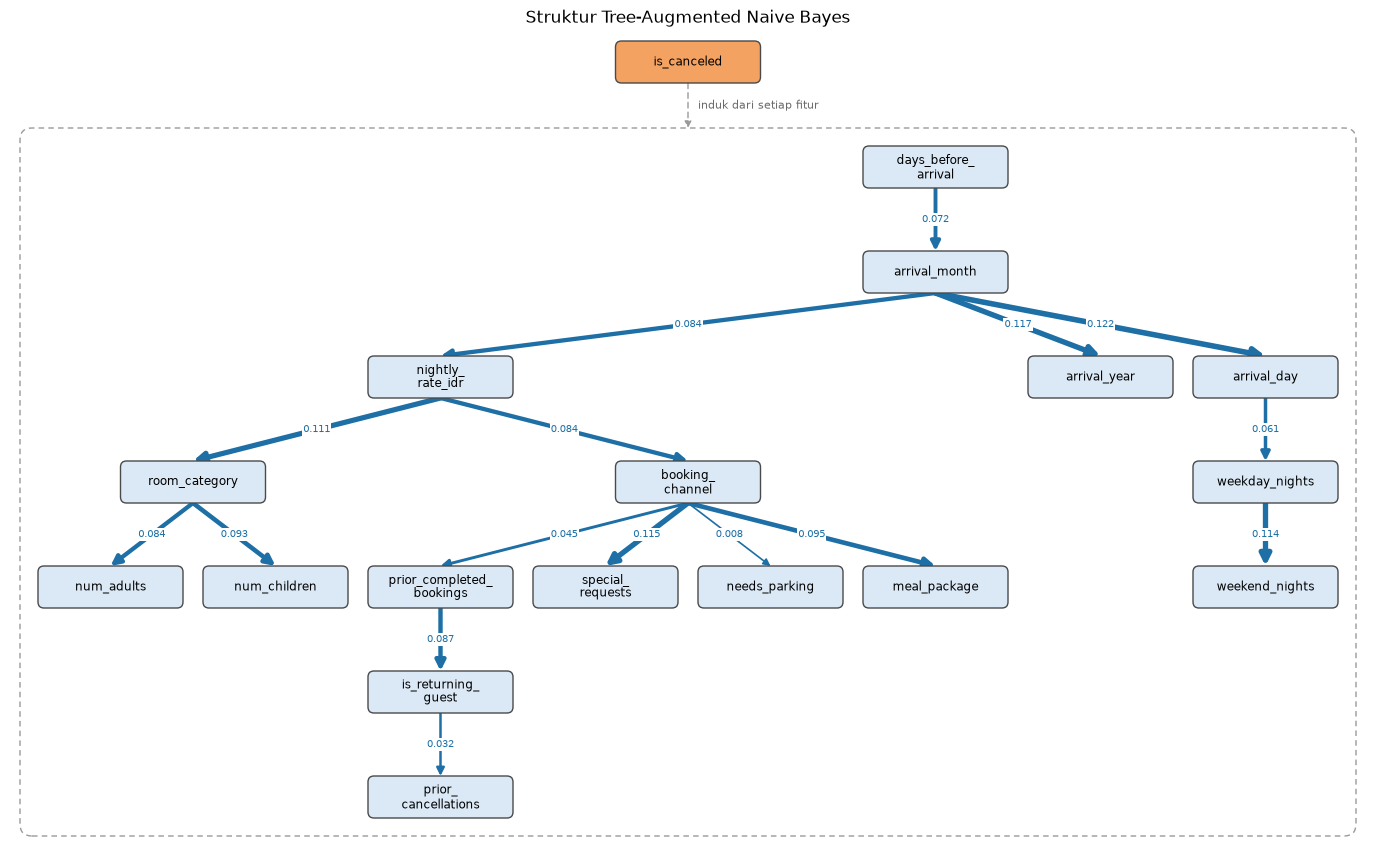

Akar pohon: days_before_arrival
                  parent                    child    cmi
           arrival_month              arrival_day 0.1216
           arrival_month             arrival_year 0.1168
         booking_channel         special_requests 0.1150
          weekday_nights           weekend_nights 0.1144
        nightly_rate_idr            room_category 0.1108
         booking_channel             meal_package 0.0948
           room_category             num_children 0.0927
prior_completed_bookings       is_returning_guest 0.0874
        nightly_rate_idr          booking_channel 0.0843
           arrival_month         nightly_rate_idr 0.0843
           room_category               num_adults 0.0840
     days_before_arrival            arrival_month 0.0721
             arrival_day           weekday_nights 0.0612
         booking_channel prior_completed_bookings 0.0446
      is_returning_guest      prior_cancellations 0.0322
         booking_channel            needs_parking 0.0084

In [40]:
tan_full = TreeAugmentedNaiveBayes(alpha=1).fit(X_train_nb, y_train.to_numpy())
ax = plot_bayesian_network(tan_full, DISCRETE_COLUMNS)
ax.set_title('Struktur Tree-Augmented Naive Bayes')
ax.figure.savefig(CFG.OUTPUT_DIR / 'naive_bayes_tan_graph.png', dpi=150, bbox_inches='tight')
plt.show()

tan_edges = pd.DataFrame(
    [(DISCRETE_COLUMNS[parent], DISCRETE_COLUMNS[child], weight) for parent, child, weight in tan_full.edges_],
    columns=['parent', 'child', 'cmi'],
).sort_values('cmi', ascending=False)
print('Akar pohon:', DISCRETE_COLUMNS[tan_full.root_])
print(tan_edges.round(4).to_string(index=False))

Akar pohon adalah `days_before_arrival`, fitur dengan *mutual information* terbesar terhadap kelas. Hasil ini sejalan dengan eksplorasi data, yang menunjukkan bahwa peluang batal naik tajam seiring bertambahnya jarak antara pemesanan dan kedatangan. Arah panah mengikuti akar pohon, bukan hubungan sebab-akibat. Sisi yang terbentuk juga masuk akal secara domain:

- `arrival_month` menjadi parent `arrival_day`, `arrival_year`, dan `nightly_rate_idr`. Komponen tanggal kedatangan saling terkait, dan harga mengikuti musim.
- `weekday_nights` → `weekend_nights` menghubungkan dua bagian dari lama menginap yang sama.
- `nightly_rate_idr` → `room_category` → `num_adults` dan `num_children` menghubungkan harga, tipe kamar, dan jumlah tamu.
- `booking_channel` menjadi parent `special_requests`, `meal_package`, dan `prior_completed_bookings` karena kebiasaan tamu berbeda pada setiap kanal pemesanan.
- `prior_completed_bookings` → `is_returning_guest` → `prior_cancellations` mengelompokkan riwayat tamu.

Sisi terlemah adalah `booking_channel` → `needs_parking` dengan CMI 0,008. Pohon pada TAN harus menghubungkan semua fitur, sehingga fitur yang hampir independen tetap mendapat satu parent. Pengaruhnya pada prediksi kecil karena peluang `needs_parking` hampir sama untuk setiap kanal setelah kelasnya diketahui.

### Penyetelan Preprocessing dan Training Naive Bayes

Pipeline `nb` membagi `days_before_arrival` dan `nightly_rate_idr` ke dalam lima bin. Bin yang kasar menyatukan pemesanan dengan lead time yang sangat berbeda, padahal peluang batal berubah tajam terhadap lead time. Karena itu, jumlah bin (5, 10, 20, atau 30) dipilih lewat 5-fold CV pada `train_set`, dengan `days_before_arrival` yang kosong diisi dari pemesanan serupa sebelum dibagi ke bin. Threshold peluang kelas batal dipilih dari prediksi out-of-fold yang sama, lalu model akhir dilatih pada seluruh `train_set`.

In [41]:
NB_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
NB_BINS = (5, 10, 20, 30)
nb_model_classes = {'Naive Bayes': NaiveBayes, 'Naive Bayes TAN': TreeAugmentedNaiveBayes}

# Imputasi saudara cukup sekali per fold; jumlah bin hanya mengubah langkah diskretisasi.
nb_imputed_folds = []
for fit_rows, eval_rows in NB_CV.split(train_set, y_train_array):
    imputer = SiblingImputer().fit(train_set.iloc[fit_rows])
    nb_imputed_folds.append((fit_rows, eval_rows, imputer.transform(train_set.iloc[fit_rows]),
                             imputer.transform(train_set.iloc[eval_rows])))

nb_search = []
for n_bins in NB_BINS:
    fold_matrices = []
    for fit_rows, eval_rows, fit_frame, eval_frame in nb_imputed_folds:
        fold_prep = make_discrete_preprocessor(n_bins).fit(fit_frame)
        fold_matrices.append((fit_rows, eval_rows, fold_prep.transform(fit_frame), fold_prep.transform(eval_frame)))
    for name, model_class in nb_model_classes.items():
        oof = np.zeros(len(train_set))
        for fit_rows, eval_rows, X_fold_fit, X_fold_eval in fold_matrices:
            oof[eval_rows] = model_class(alpha=1).fit(X_fold_fit, y_train_array[fit_rows]).predict_proba(X_fold_eval)[:, 1]
        threshold, score = best_threshold(y_train_array, oof)
        nb_search.append({'model': name, 'n_bins': n_bins, 'threshold': threshold, 'cv_macro_f1': score})
nb_search = pd.DataFrame(nb_search)
print(nb_search.pivot(index='n_bins', columns='model', values='cv_macro_f1').round(4).to_string())

nb_ablation = []
for name, model_class in nb_model_classes.items():
    best = nb_search[nb_search['model'] == name].sort_values('cv_macro_f1', ascending=False).iloc[0]
    n_bins, threshold = int(best['n_bins']), float(best['threshold'])
    final_prep = make_discrete_preprocessor(n_bins, sibling_imputation=True).fit(train_set)
    X_fit, X_eval = final_prep.transform(train_set), final_prep.transform(val_set)
    start = perf_counter()
    final = model_class(alpha=1, threshold=threshold).fit(X_fit, y_train_array)
    fit_seconds = perf_counter() - start
    baseline = next(row for row in results if row['model'] == name)['macro_f1']
    predicted = replace_result(name, f'nb_{n_bins}', lambda model_class=model_class, threshold=threshold:
                               model_class(alpha=1, threshold=threshold), final, X_fit, X_eval, y_train_array, fit_seconds)
    nb_ablation.append({'model': name, 'awal (5.000 baris, 5 bin)': baseline,
                        'train_set + bin CV (argmax)': f1_score(y_valid, model_class(alpha=1).fit(X_fit, y_train_array).predict(X_eval), average='macro'),
                        '+ threshold CV (final)': f1_score(y_valid, predicted, average='macro'),
                        'n_bins': n_bins, 'threshold': threshold})
print(pd.DataFrame(nb_ablation).round(4).to_string(index=False))

D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


model   Naive Bayes  Naive Bayes TAN
n_bins                              
5            0.7486           0.7688
10           0.7473           0.7704
20           0.7502           0.7804
30           0.7507           0.7823


D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\---Kuliah\Semester 5\IF3170_G13_brownbear\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


          model  awal (5.000 baris, 5 bin)  train_set + bin CV (argmax)  + threshold CV (final)  n_bins  threshold
    Naive Bayes                     0.7371                       0.7505                  0.7494      30       0.49
Naive Bayes TAN                     0.7453                       0.7740                  0.7784      30       0.42


Jumlah bin yang lebih halus paling membantu TAN: macro F1 CV naik dari 0,769 (5 bin) menjadi 0,782 (30 bin), dan macro F1 validasi naik dari 0,745 pada perbandingan awal menjadi 0,778. Bin yang halus memisahkan pemesanan dengan lead time dan harga yang berbeda jauh, dan TAN dapat memperkirakan peluang setiap bin dengan baik karena setiap fitur bergantung pada satu parent. Naive Bayes biasa hanya naik dari 0,737 menjadi 0,749. Asumsi independennya tetap menghitung informasi yang sama berulang kali, sehingga bin yang lebih halus tidak banyak membantu.

Peringatan dari `KBinsDiscretizer` muncul karena banyak pemesanan memiliki `days_before_arrival` dan harga yang sama persis. Beberapa batas kuantil bernilai sama, sehingga bin yang terlalu sempit digabung dan jumlah bin efektifnya sedikit di bawah 30.

<!-- figure palette: #6d2fa3 -->

## Model Evaluation

This part compares the validation results of all models.

In [42]:
results_df = pd.DataFrame(results).sort_values(
    ['macro_f1', 'accuracy'], ascending=False
).reset_index(drop=True)
print(results_df.round(4).to_string(index=False))
best_name = results_df.loc[0, 'model']
print('Model dengan macro F1 validasi tertinggi:', best_name)

             model  macro_f1  accuracy  fit_seconds  predict_seconds
              CART    0.8389    0.8595      12.9245           0.5569
               KNN    0.8324    0.8566       0.0016           7.1178
      SVM Gaussian    0.8216    0.8438      99.5680           1.3476
    SVM Polynomial    0.7942    0.8184       5.2049           0.4838
         LogReg L1    0.7904    0.8155       0.9982           0.0005
LogReg Elastic Net    0.7892    0.8133       2.2491           0.0012
         LogReg L2    0.7887    0.8140       3.0935           0.0017
   Naive Bayes TAN    0.7784    0.8047       0.0542           0.0043
        SVM Linear    0.7684    0.7983      15.7508           0.0503
       Naive Bayes    0.7494    0.7833       0.0123           0.0032
Model dengan macro F1 validasi tertinggi: CART


Macro F1 menjadi dasar pemilihan model karena kedua kelas diberi bobot penilaian yang sama. Model diurutkan berdasarkan macro F1 pada data validasi. Jika nilainya sama, akurasi menjadi pembanding kedua sebelum pelatihan akhir.

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [43]:
# Threshold KNN dipilih dari prediksi out-of-fold 5-fold CV pada train_set saja; val_set tidak disentuh.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
oof_knn = np.zeros(len(train_set))
for fit_rows, eval_rows in cv.split(train_set, y_train_array):
    fold_prep = make_knn_preprocessor().fit(train_set.iloc[fit_rows])
    fold_model = KNN(**knn_params).fit(fold_prep.transform(train_set.iloc[fit_rows]), y_train_array[fit_rows])
    oof_knn[eval_rows] = fold_model.predict_proba(fold_prep.transform(train_set.iloc[eval_rows]))[:, 1]

thresholds = np.round(np.arange(.40, .561, .01), 2)
threshold_scores = pd.Series(
    [f1_score(y_train_array, (oof_knn >= t).astype(int), average='macro') for t in thresholds], index=thresholds)
BEST_THRESHOLD = float(threshold_scores.idxmax())
print('Macro F1 out-of-fold per threshold:')
print(threshold_scores.round(4).to_string())
print('Threshold terpilih:', BEST_THRESHOLD)


def make_final_knn():
    return KNN(**knn_params, threshold=BEST_THRESHOLD)


# KNN akhir dilatih pada seluruh train_set lalu diuji pada val_set.
start = perf_counter()
knn_final = make_final_knn().fit(X_train_knn, y_train_array)
knn_fit_seconds = perf_counter() - start
knn_predicted = replace_result('KNN', 'knn', make_final_knn, knn_final,
                               X_train_knn, X_val_knn, y_train_array, knn_fit_seconds)
results_df = pd.DataFrame(results).sort_values(['macro_f1', 'accuracy'], ascending=False).reset_index(drop=True)
best_name = results_df.loc[0, 'model']
print(results_df[['model', 'macro_f1', 'accuracy']].round(4).to_string(index=False))
print('Model akhir:', best_name)

Macro F1 out-of-fold per threshold:
0.40    0.8509
0.41    0.8522
0.42    0.8535
0.43    0.8539
0.44    0.8539
0.45    0.8546
0.46    0.8541
0.47    0.8546
0.48    0.8543
0.49    0.8538
0.50    0.8534
0.51    0.8530
0.52    0.8528
0.53    0.8521
0.54    0.8516
0.55    0.8501
0.56    0.8484
Threshold terpilih: 0.47


             model  macro_f1  accuracy
               KNN    0.8621    0.8798
              CART    0.8389    0.8595
      SVM Gaussian    0.8216    0.8438
    SVM Polynomial    0.7942    0.8184
         LogReg L1    0.7904    0.8155
LogReg Elastic Net    0.7892    0.8133
         LogReg L2    0.7887    0.8140
   Naive Bayes TAN    0.7784    0.8047
        SVM Linear    0.7684    0.7983
       Naive Bayes    0.7494    0.7833
Model akhir: KNN


Threshold dipilih dari prediksi out-of-fold 5-fold CV pada `train_set` saja, sehingga `val_set` baru dipakai saat evaluasi akhir. Macro F1 cukup stabil pada threshold 0,44–0,50 dengan selisih di bawah 0,002, dan nilai terbaik ada di 0,47. Threshold sedikit di bawah 0,5 karena kelas batal adalah kelas minoritas.

Setelah dilatih pada seluruh `train_set`, KNN mencapai macro F1 validasi 0,862, naik dari 0,832 pada perbandingan 5.000 baris dan di atas DTL (0,839), SVM Gaussian (0,822), dan Logistic Regression (0,790) yang sudah disetel. Peningkatan KNN berasal dari tiga hal: penalti untuk atribut diskret yang berbeda, imputasi `days_before_arrival` dari pemesanan serupa, dan bobot fitur hasil *coordinate descent*.

Bobot fitur KNN dicari dengan *coordinate descent*. Setiap fitur dicoba satu per satu dengan bobot 0, 0,6 kali, dan 1,6 kali bobot saat ini (atau 0,3 dan 1 jika bobotnya masih 0). Perubahan disimpan jika macro F1 out-of-fold naik lebih dari 0,0002, dan proses diulang hingga tidak ada lagi perbaikan. Metode ini mengoptimasi satu koordinat pada satu waktu sambil mempertahankan koordinat lain, sehingga cocok untuk fungsi objektif seperti macro F1 yang tidak dapat diturunkan [Wright, 2015].

Pencarian ini memakan waktu lama karena setiap evaluasi menjalankan 5-fold KNN. Karena itu, hasilnya disimpan sebagai `KNN_FEATURE_WEIGHTS` di `preprocessing.py`. Fungsi di bawah disertakan agar prosesnya dapat diulang, tetapi tidak dijalankan secara bawaan.

Bobot ini dipakai oleh model submisi yang dilatih ulang pada seluruh data berlabel, sehingga pencariannya memakai CV pada seluruh data tersebut, termasuk baris `val_set`. Akibatnya, skor validasi KNN di atas sedikit optimis dan sebaiknya dibaca bersama macro F1 out-of-fold pada `train_set` (0,855).

In [44]:
RUN_WEIGHT_SEARCH = False
# Bobot dipakai oleh model submisi yang dilatih pada seluruh data berlabel,
# sehingga pencariannya memakai CV pada seluruh data tersebut.
y_all = train_df['is_canceled'].to_numpy()
full_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)

def knn_cv_score(weights):
    probabilities = np.zeros(len(train_df))
    for fit_rows, eval_rows in full_cv.split(train_df, y_all):
        fold_prep = make_knn_preprocessor(weights).fit(train_df.iloc[fit_rows])
        fold_model = KNN(**{**knn_params, 'mismatch_groups': fold_prep.mismatch_groups_,
                            'tolerances': fold_prep.tolerances_})
        fold_model.fit(fold_prep.transform(train_df.iloc[fit_rows]), y_all[fit_rows])
        probabilities[eval_rows] = fold_model.predict_proba(
            fold_prep.transform(train_df.iloc[eval_rows]))[:, 1]
    return max(f1_score(y_all, (probabilities >= t).astype(int), average='macro') for t in thresholds)

def coordinate_descent(weights, max_pass=3, min_gain=2e-4):
    weights, best = dict(weights), knn_cv_score(weights)
    for _ in range(max_pass):
        improved = False
        for column in knn_features.columns:
            current = weights.get(column, 0.0)
            for value in ([0.0, .6 * current, 1.6 * current] if current else [.3, 1.0]):
                score = knn_cv_score({**weights, column: value})
                if score > best + min_gain:
                    weights[column], best, improved = value, score, True
                    break
        if not improved:
            break
    return weights, best

if RUN_WEIGHT_SEARCH:
    searched_weights, searched_score = coordinate_descent(KNN_FEATURE_WEIGHTS)
    print(searched_score, searched_weights)

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [45]:
SKLEARN_SVM_KERNELS = {'linear': 'linear', 'polynomial': 'poly', 'gaussian': 'rbf'}


def sklearn_logreg(name):
    # Objektif kami: rata-rata log-loss + reg_strength * penalti, sedangkan scikit-learn memakai
    # penalti + C * jumlah log-loss. Keduanya sama jika C = 1 / (reg_strength * n).
    params = logreg_params[name]
    l1_ratio = {'l1': 1., 'l2': 0., 'elasticnet': params.get('l1_ratio', .5)}[params['penalty']]
    C = 1 / (params['reg_strength'] * len(model_inputs[model_factories[name][0]][2]))
    return SkLogisticRegression(l1_ratio=l1_ratio, C=C, solver='lbfgs' if l1_ratio == 0 else 'saga',
                                tol=1e-5, max_iter=5000, random_state=CFG.SEED)


def sklearn_svm(kernel):
    params = {key: value for key, value in svm_params[kernel].items()
              if key in ('C', 'gamma', 'degree', 'coef0', 'class_weight')}
    return SVC(kernel=SKLEARN_SVM_KERNELS[kernel], **params)


def inverse_distance_votes(distances, power=knn_params['vote_power']):
    """Bobot suara 1 / d^power; jika ada tetangga berjarak nol, hanya tetangga itu yang memberi suara."""
    exact = distances == 0
    with np.errstate(divide='ignore'):
        votes = distances ** -power
    return np.where(exact.any(axis=1, keepdims=True), exact, votes)


def sklearn_predict(model, X_eval, threshold):
    if isinstance(model, SVC):
        return (model.decision_function(X_eval) > (threshold or 0)).astype(int)
    if threshold is None:
        return model.predict(X_eval)
    return (model.predict_proba(X_eval)[:, 1] >= threshold).astype(int)


sklearn_factories = {
    'KNN': lambda: KNeighborsClassifier(n_neighbors=knn_params['k'], metric=knn_params['metric'],
                                         weights=inverse_distance_votes),
    'CART': lambda: DecisionTreeClassifier(criterion='gini', ccp_alpha=DTL_PARAMS['ccp_alpha'],
                                            class_weight=DTL_PARAMS['class_weight'], random_state=CFG.SEED),
    **{name: (lambda name=name: sklearn_logreg(name)) for name in logreg_params},
    **{f'SVM {kernel.capitalize()}': (lambda kernel=kernel: sklearn_svm(kernel)) for kernel in svm_params},
    'Naive Bayes': lambda: CategoricalNB(alpha=1),
}
knn_columns = len(knn_prep.columns_)
sklearn_results, sklearn_predictions = [], {}
for name, factory in sklearn_factories.items():
    if name == 'KNN':
        X_fit, X_eval, y_fit = X_train_knn[:, :knn_columns], X_val_knn[:, :knn_columns], y_train.to_numpy()
        threshold = BEST_THRESHOLD
    elif name == 'CART':
        X_fit, X_eval, y_fit = X_train_tree_sk, X_val_tree_sk, y_train.to_numpy()
        threshold = DTL_PARAMS['threshold']
    else:
        X_fit, X_eval, y_fit = model_inputs[model_factories[name][0]]
        threshold = getattr(models[name], 'threshold', None)
    start = perf_counter()
    model = factory().fit(X_fit, y_fit)
    fit_seconds = perf_counter() - start
    predicted = sklearn_predict(model, X_eval, threshold)
    sklearn_predictions[name] = predicted
    sklearn_results.append({
        'model': name,
        'sklearn_macro_f1': f1_score(y_valid, predicted, average='macro'),
        'sklearn_accuracy': accuracy_score(y_valid, predicted),
        'agreement': np.mean(predicted == predictions[name]),
        'sklearn_fit_seconds': fit_seconds,
    })
comparison_df = results_df.merge(pd.DataFrame(sklearn_results), on='model')
print(comparison_df.round(4).to_string(index=False))

# Konfigurasi setara tanpa penalti, sehingga perbedaan yang tersisa hanya implementasi.
X_fit_plain, X_eval_plain = X_train_knn[:, :knn_columns], X_val_knn[:, :knn_columns]
reference_knn = KNN(k=knn_params['k'], metric=knn_params['metric'], weights='distance',
                    vote_power=knn_params['vote_power'], threshold=BEST_THRESHOLD)
reference_pred = reference_knn.fit(X_fit_plain, y_train_array).predict(X_eval_plain)
sklearn_reference = sklearn_factories['KNN']().fit(X_fit_plain, y_train_array)
print('KNN tanpa penalti vs scikit-learn dengan konfigurasi setara, kesamaan prediksi:',
      np.mean(reference_pred == sklearn_predict(sklearn_reference, X_eval_plain, BEST_THRESHOLD)))

             model  macro_f1  accuracy  fit_seconds  predict_seconds  sklearn_macro_f1  sklearn_accuracy  agreement  sklearn_fit_seconds
               KNN    0.8621    0.8798       0.0053          45.1985            0.8592            0.8772     0.9668               0.0025
              CART    0.8389    0.8595      12.9245           0.5569            0.8383            0.8588     0.9832               0.2611
      SVM Gaussian    0.8216    0.8438      99.5680           1.3476            0.8214            0.8436     0.9998              18.4782
    SVM Polynomial    0.7942    0.8184       5.2049           0.4838            0.7942            0.8184     1.0000               0.9864
         LogReg L1    0.7904    0.8155       0.9982           0.0005            0.7902            0.8153     0.9998               2.2480
LogReg Elastic Net    0.7892    0.8133       2.2491           0.0012            0.7889            0.8131     0.9998               6.5307
         LogReg L2    0.7887    0.8140   

KNN tanpa penalti vs scikit-learn dengan konfigurasi setara, kesamaan prediksi: 1.0


Setiap model dibandingkan dengan pasangan scikit-learn pada data training, hyperparameter, dan threshold yang sama dengan model akhirnya. Untuk Logistic Regression, kekuatan regularisasi kami diubah menjadi `C = 1 / (reg_strength × n)` karena scikit-learn menjumlahkan log-loss, sedangkan implementasi kami merata-ratakannya. Threshold SVM diterapkan pada nilai keputusan, dan threshold Naive Bayes serta Logistic Regression pada peluang kelas batal. Pohon scikit-learn memakai fitur DTL yang sama, tetapi kategori di-one-hot karena implementasinya membutuhkan masukan numerik. Nilai kosong tetap NaN karena `DecisionTreeClassifier` mendukung missing value secara bawaan. Kedua pohon memakai `criterion='gini'`, `ccp_alpha`, `class_weight`, dan threshold yang sama, serta dilatih pada seluruh `train_set`. TAN tidak ikut dibandingkan karena scikit-learn tidak menyediakan Naive Bayes dengan struktur pohon. Tabel peluangnya dihitung dengan kode yang sama seperti Naive Bayes kami, yang prediksinya identik dengan `CategoricalNB`.

`KNeighborsClassifier` tidak mendukung penalti untuk atribut yang berbeda, sehingga pembandingnya hanya memakai bagian fitur berbobot dari matriks KNN. Selain penalti, konfigurasinya dibuat sama: bobot suara $1/d^{1{,}5}$ diberikan lewat fungsi `weights`, dan threshold 0,47 diterapkan pada `predict_proba`. Dengan begitu, selisih skor keduanya (0,862 vs 0,859) hanya berasal dari penalti. Ketika penalti juga dihilangkan dari KNN kami, prediksinya sama persis dengan scikit-learn, sehingga perhitungan jarak, voting berbobot, dan threshold-nya sudah benar.

## Visualisasi Perbandingan per Model

Setiap gambar menampilkan macro F1 implementasi sendiri dan scikit-learn pada `val_set`, serta confusion matrix keduanya untuk konfigurasi akhir.

In [46]:
SCRATCH_COLOR, SKLEARN_COLOR = '#2a9d8f', '#8c8c8c'


def plot_vs_sklearn(title, names, labels, cm_name, file_name):
    """Macro F1 from scratch vs scikit-learn per varian, lalu confusion matrix keduanya untuk `cm_name`."""
    rows = comparison_df.set_index('model').loc[list(names)]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'width_ratios': [1.3, 1, 1]})
    x, width = np.arange(len(names)), .38
    for offset, column, label, color in [(-width / 2, 'macro_f1', 'from scratch', SCRATCH_COLOR),
                                         (width / 2, 'sklearn_macro_f1', 'scikit-learn', SKLEARN_COLOR)]:
        bars = axes[0].bar(x + offset, rows[column], width, label=label, color=color)
        axes[0].bar_label(bars, fmt='%.4f', fontsize=8)
    axes[0].set_xticks(x, labels)
    axes[0].set_ylim(0, 1.15)  # mulai dari 0 agar selisih kecil tidak terlihat dibesar-besarkan
    axes[0].set_ylabel('macro F1 val_set')
    axes[0].set_title(f'{title} from scratch vs scikit-learn')
    axes[0].legend(fontsize=8, loc='upper center', ncol=2)
    cm_label = labels[list(names).index(cm_name)]
    for ax, library, predicted in [(axes[1], 'from scratch', predictions[cm_name]),
                                   (axes[2], 'scikit-learn', sklearn_predictions[cm_name])]:
        ConfusionMatrixDisplay.from_predictions(y_valid, predicted, display_labels=['tidak batal', 'batal'],
                                                cmap='Blues', colorbar=False, ax=ax)
        ax.set_title(f'{library} ({cm_label})')
    fig.tight_layout()
    fig.savefig(CFG.OUTPUT_DIR / file_name, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Kesamaan prediksi {cm_label}: {rows.loc[cm_name, "agreement"]:.2%}')


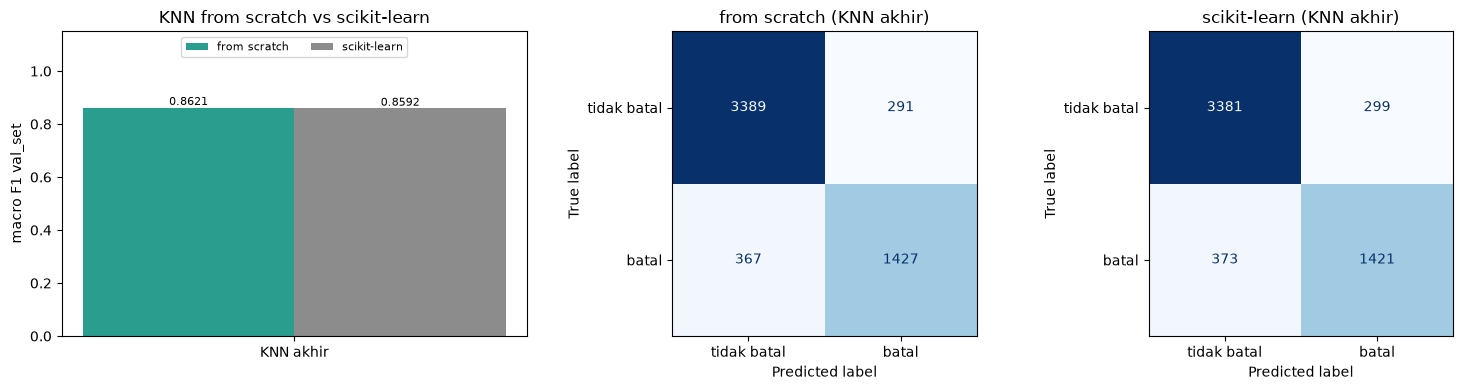

Kesamaan prediksi KNN akhir: 96.68%


In [47]:
plot_vs_sklearn('KNN', ['KNN'], ['KNN akhir'], 'KNN', 'knn_vs_sklearn.png')

Pada KNN, macro F1 implementasi kami 0,8621 dan scikit-learn 0,8592 dengan kesamaan prediksi 96,68% (false positive 291 vs 299, false negative 367 vs 373). Selisihnya hanya berasal dari penalti atribut yang tidak didukung `KNeighborsClassifier`; tanpa penalti, prediksi keduanya identik.

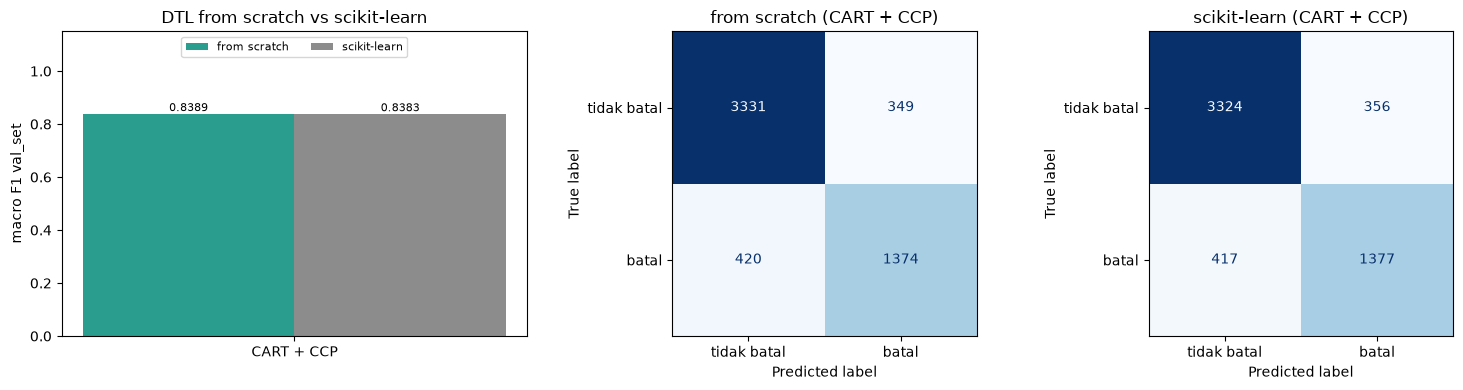

Kesamaan prediksi CART + CCP: 98.32%


In [48]:
plot_vs_sklearn('DTL', ['CART'], ['CART + CCP'], 'CART', 'dtl_vs_sklearn.png')

Pada DTL, macro F1 implementasi kami 0,8389 dan scikit-learn 0,8383 dengan kesamaan prediksi 98,32% (false positive 349 vs 356, false negative 420 vs 417). Sisa perbedaannya berasal dari split kategori sebagai himpunan pada pohon kami, sedangkan scikit-learn memecah satu kolom one-hot per split.

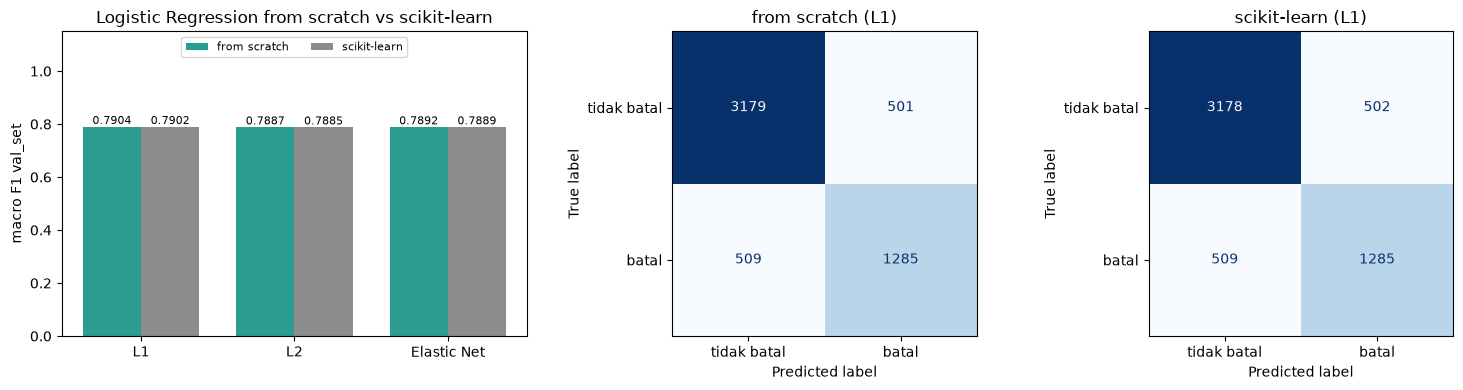

Kesamaan prediksi L1: 99.98%


In [49]:
plot_vs_sklearn('Logistic Regression', ['LogReg L1', 'LogReg L2', 'LogReg Elastic Net'],
                ['L1', 'L2', 'Elastic Net'], 'LogReg L1', 'logreg_vs_sklearn.png')

Pada Logistic Regression, selisih macro F1 ketiga regularisasi paling besar 0,0003. Prediksi L1 hanya berbeda pada satu dari 5.474 baris (false positive 501 vs 502).

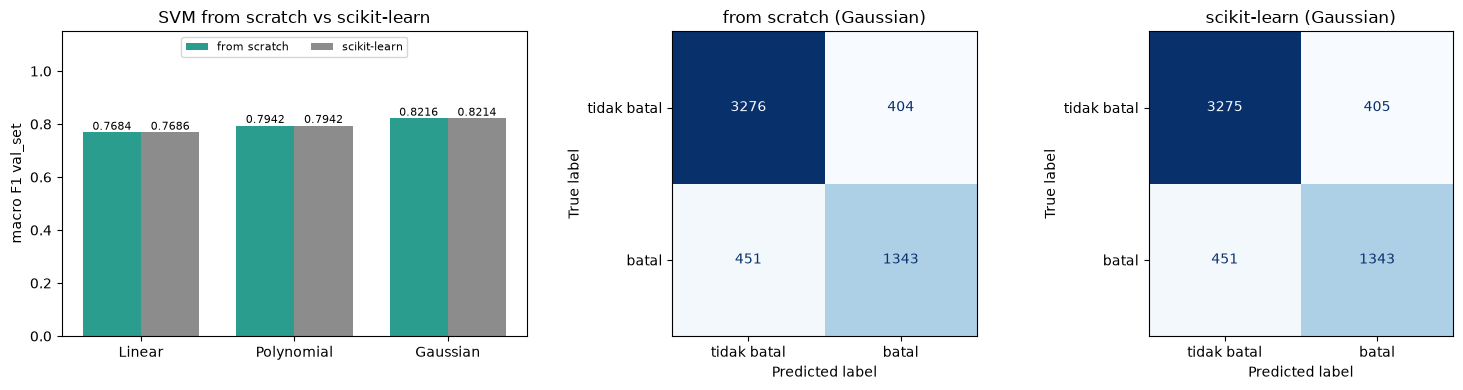

Kesamaan prediksi Gaussian: 99.98%


In [50]:
plot_vs_sklearn('SVM', ['SVM Linear', 'SVM Polynomial', 'SVM Gaussian'],
                ['Linear', 'Polynomial', 'Gaussian'], 'SVM Gaussian', 'svm_vs_sklearn.png')

Pada SVM, selisih macro F1 ketiga kernel paling besar 0,0002. Pada kernel Gaussian, prediksi hanya berbeda pada satu baris (false positive 404 vs 405) karena `SVC` juga menjalankan SMO dengan *second-order working set selection*.

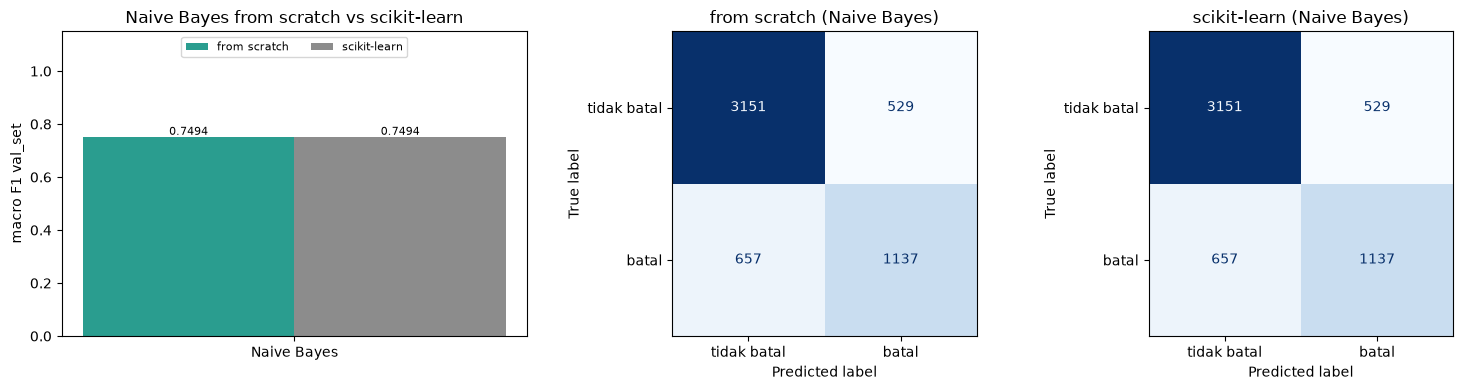

Kesamaan prediksi Naive Bayes: 100.00%


In [51]:
plot_vs_sklearn('Naive Bayes', ['Naive Bayes'], ['Naive Bayes'], 'Naive Bayes', 'naive_bayes_vs_sklearn.png')

Prediksi Naive Bayes identik dengan `CategoricalNB` pada seluruh 5.474 baris, sehingga confusion matrix keduanya sama persis.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [52]:
saved_models = {}
for name, model in models.items():
    path = CFG.OUTPUT_DIR / (name.lower().replace(' ', '_') + '.pkl')
    model.save(path)
    restored = type(model).load(path)
    X_eval = model_inputs[model_factories[name][0]][1]
    np.testing.assert_array_equal(restored.predict(X_eval[:20]), predictions[name][:20])
    saved_models[name] = path
print('Model yang berhasil disimpan dan dimuat kembali:', len(saved_models))

Model yang berhasil disimpan dan dimuat kembali: 10


Setiap model disimpan lalu dimuat kembali sebelum hasil prediksinya dibandingkan. Pemeriksaan ini memastikan berkas model dapat dipakai ulang tanpa melatih ulang.

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [53]:
# Tiga konfigurasi KNN yang dipilih sebagai submisi final Kaggle.
DATE_PENALTY, ROOM_PENALTY = ('arrival_year', 'arrival_month', 'arrival_day'), ('room_category',)
FINAL_SUBMISSIONS = {
    'submission1.csv': dict(penalties={DATE_PENALTY: .7}, k=35, vote_power=2.0, threshold=.47),
    'submission2.csv': dict(penalties={ROOM_PENALTY: .4}, k=29, vote_power=1.5, threshold=.49),
    'submission3.csv': dict(penalties={}, k=25, vote_power=1.5, threshold=.46),
}
y_full = train_df['is_canceled'].to_numpy()
submission_rows = []
for file_name, config in FINAL_SUBMISSIONS.items():
    stem = file_name.removesuffix('.csv')
    penalties = {**KNN_MISMATCH_PENALTIES, **config['penalties']}
    final_prep = make_knn_preprocessor(mismatch_penalties=penalties).fit(train_df)
    final_model = KNN(k=config['k'], metric='manhattan', weights='distance', vote_power=config['vote_power'],
                      threshold=config['threshold'], mismatch_groups=final_prep.mismatch_groups_,
                      tolerances=final_prep.tolerances_).fit(final_prep.transform(train_df), y_full)
    final_model.save(CFG.OUTPUT_DIR / f'knn_{stem}.pkl')
    with (CFG.OUTPUT_DIR / f'knn_{stem}_preprocessor.pkl').open('wb') as file:
        pickle.dump(final_prep, file)

    restored_model = KNN.load(CFG.OUTPUT_DIR / f'knn_{stem}.pkl')
    with (CFG.OUTPUT_DIR / f'knn_{stem}_preprocessor.pkl').open('rb') as file:
        restored_prep = pickle.load(file)
    submission = pd.DataFrame({
        'id': test_ids,
        'is_canceled': restored_model.predict(restored_prep.transform(test_df)).astype(int),
    })
    assert submission.columns.tolist() == ['id', 'is_canceled']
    assert len(submission) == len(test_df) and submission['id'].equals(test_ids)
    assert submission['is_canceled'].isin([0, 1]).all()
    submission.to_csv(CFG.OUTPUT_DIR / file_name, index=False)
    changed = {', '.join(group): value for group, value in config['penalties'].items()} or 'bawaan'
    submission_rows.append({'file': file_name, 'penalti_diubah': changed, 'k': config['k'],
                            'vote_power': config['vote_power'], 'threshold': config['threshold'],
                            'proporsi_batal': submission['is_canceled'].mean(), 'baris': len(submission)})
print(pd.DataFrame(submission_rows).round(4).to_string(index=False))

           file                                    penalti_diubah  k  vote_power  threshold  proporsi_batal  baris
submission1.csv {'arrival_year, arrival_month, arrival_day': 0.7} 35         2.0       0.47          0.3112   6844
submission2.csv                            {'room_category': 0.4} 29         1.5       0.49          0.3048   6844
submission3.csv                                            bawaan 25         1.5       0.46          0.3133   6844


In [54]:
# Banyaknya baris test yang prediksinya berbeda antarberkas submisi.
submission_labels = {name: pd.read_csv(CFG.OUTPUT_DIR / name)['is_canceled'] for name in FINAL_SUBMISSIONS}
names = list(submission_labels)
for i, first in enumerate(names):
    for second in names[i + 1:]:
        changed = int((submission_labels[first] != submission_labels[second]).sum())
        print(f'{first} vs {second}: {changed} baris berbeda')

submission1.csv vs submission2.csv: 86 baris berbeda
submission1.csv vs submission3.csv: 94 baris berbeda
submission2.csv vs submission3.csv: 66 baris berbeda


Ketiga submisi memakai KNN, model dengan macro F1 validasi tertinggi. Pipeline dan model dilatih ulang pada seluruh data berlabel, sedangkan data test hanya ditransformasi, dan imputasi pemesanan serupa untuk data test hanya merujuk ke data training. Setiap model serta pipeline disimpan, dimuat kembali, lalu dipakai untuk membuat berkas CSV.

| Berkas | Konfigurasi | Alasan |
|---|---|---|
| `submission1.csv` | penalti tanggal kedatangan 0,7, k = 35, vote power 2,0, threshold 0,47 | Jumlah tetangga lebih banyak, dengan bobot suara yang lebih besar untuk tetangga terdekat |
| `submission2.csv` | penalti kategori kamar 0,4, k = 29, threshold 0,49 | Pemesanan dengan kamar berbeda lebih jarang dianggap pemesanan serupa |
| `submission3.csv` | konfigurasi utama KNN (k = 25, vote power 1,5) dengan threshold 0,46 | Konfigurasi utama yang tervalidasi pada dua pembagian fold |

Prediksi ketiga konfigurasi hanya berbeda pada 66–94 dari 6.844 baris test, seperti dihitung pada sel sebelumnya. Memilih ketiganya sebagai submisi final memberi beberapa variasi model dengan kualitas yang setara.

Berbeda dengan evaluasi validasi, konfigurasi submisi dipilih dengan CV pada seluruh data berlabel, karena model akhirnya juga dilatih pada seluruh data tersebut.

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [55]:
best_pred = predictions[best_name]
matrix = confusion_matrix(y_valid, best_pred, labels=[0, 1])
false_positive, false_negative = int(matrix[0, 1]), int(matrix[1, 0])
print('Confusion matrix:')
print(matrix)
print(classification_report(y_valid, best_pred, digits=4))
print('False positive:', false_positive, 'False negative:', false_negative)

error_rows = val_set[['booking_channel']].copy()
error_rows['error'] = best_pred != y_valid
print(error_rows.groupby('booking_channel')['error'].agg(
    total='size', error_rate='mean').round(4))

oof_error = (oof_knn >= BEST_THRESHOLD).astype(int) != y_train_array
missing_review = pd.DataFrame([
    {'column': column, 'missing_rows': int(mask.sum()),
     'error_when_missing': oof_error[mask].mean(), 'error_when_known': oof_error[~mask].mean()}
    for column in ['days_before_arrival', 'nightly_rate_idr', 'special_requests', 'meal_package']
    for mask in [train_set[column].isna().to_numpy()]
])
print(missing_review.round(4).to_string(index=False))
confidence = pd.qcut(pd.Series(np.abs(oof_knn - BEST_THRESHOLD)).rank(method='first'), 5,
                     labels=['paling ragu', '2', '3', '4', 'paling yakin'])
print(pd.Series(oof_error).groupby(confidence, observed=True).mean().rename('error_rate').round(4))

Confusion matrix:
[[3389  291]
 [ 367 1427]]
              precision    recall  f1-score   support

           0     0.9023    0.9209    0.9115      3680
           1     0.8306    0.7954    0.8126      1794

    accuracy                         0.8798      5474
   macro avg     0.8665    0.8582    0.8621      5474
weighted avg     0.8788    0.8798    0.8791      5474

False positive: 291 False negative: 367
                     total  error_rate
booking_channel                       
Airline                 16      0.1250
Complimentary           65      0.0000
Corporate              310      0.0710
Offline Agent         1633      0.0563
Online Travel Agent   3450      0.1571
             column  missing_rows  error_when_missing  error_when_known
days_before_arrival           901              0.1654            0.1256
   nightly_rate_idr          1645              0.1003            0.1295
   special_requests          1994              0.1479            0.1252
       meal_package        

Confusion matrix memisahkan dua jenis prediksi yang salah. False positive berarti pemesanan diprediksi batal padahal sebenarnya tidak batal.

Kesalahan KNN paling banyak terjadi pada pemesanan kanal Online Travel Agent dan pada pemesanan yang `days_before_arrival`-nya kosong, karena fitur terpenting dan tanggal pemesanan ikut hilang. Imputasi pemesanan serupa sudah menurunkan error kelompok ini, tetapi error-nya masih di atas baris lain. Error juga terkumpul pada prediksi dengan peluang dekat threshold, yaitu pemesanan yang tidak memiliki pemesanan serupa di data training. Sebaliknya, prediksi dengan peluang jauh dari threshold hampir selalu benar.

## Cost-Sensitive Classification

False positive lebih mahal daripada false negative karena penginapan bisa *overbooked* jika pemesanan yang ternyata datang dianggap batal. Dengan asumsi false positive dua kali lebih mahal, biaya dihitung sebagai `2 × FP + FN`. Kami tidak melatih ulang model; yang diubah adalah threshold keputusan. Secara teori, threshold optimal untuk peluang yang terkalibrasi adalah `C_FP / (C_FP + C_FN) = 2/3` [Elkan, 2001]. Karena peluang voting KNN tidak terkalibrasi sempurna, threshold dipilih langsung dari biaya pada prediksi out-of-fold.

 threshold  false_positive  false_negative  cost  macro_f1
      0.40            1688            1234  4610    0.8509
      0.42            1573            1283  4429    0.8535
      0.44            1464            1366  4294    0.8539
      0.46            1349            1456  4154    0.8541
      0.48            1253            1531  4037    0.8543
      0.50            1153            1627  3933    0.8534
      0.52            1062            1710  3834    0.8528
      0.54             983            1794  3760    0.8516
      0.56             914            1901  3729    0.8484
      0.58             836            2011  3683    0.8455
      0.60             771            2131  3673    0.8412
      0.62             686            2219  3591    0.8398
      0.64             618            2360  3596    0.8342
      0.66             557            2471  3585    0.8300
      0.68             497            2582  3576    0.8257
      0.70             443            2728  3614    0.81

Validasi:
                macro F1 (t=0.47)  biaya (t=0.68)
false_positive           291.0000        122.0000
false_negative           367.0000        638.0000
cost                     949.0000        882.0000
macro_f1                   0.8621          0.8281


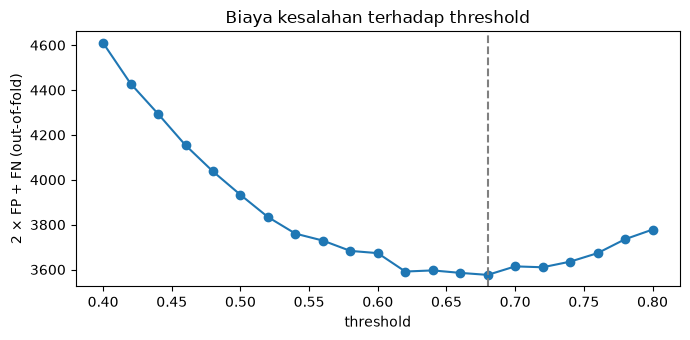

In [56]:
def booking_cost(y_true, predicted):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {'false_positive': fp, 'false_negative': fn, 'cost': 2 * fp + fn,
            'macro_f1': f1_score(y_true, predicted, average='macro')}

cost_thresholds = np.round(np.arange(.40, .801, .02), 2)
cost_table = pd.DataFrame(
    [{'threshold': t, **booking_cost(y_train_array, (oof_knn >= t).astype(int))} for t in cost_thresholds])
COST_THRESHOLD = float(cost_table.loc[cost_table['cost'].idxmin(), 'threshold'])
print(cost_table.round(4).to_string(index=False))

cost_review = pd.DataFrame({
    f'macro F1 (t={BEST_THRESHOLD})': booking_cost(y_valid, (knn_final.predict_proba(X_val_knn)[:, 1] >= BEST_THRESHOLD).astype(int)),
    f'biaya (t={COST_THRESHOLD})': booking_cost(y_valid, (knn_final.predict_proba(X_val_knn)[:, 1] >= COST_THRESHOLD).astype(int)),
})
print('Validasi:')
print(cost_review.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cost_table['threshold'], cost_table['cost'], marker='o')
ax.axvline(COST_THRESHOLD, linestyle='--', color='gray')
ax.set_xlabel('threshold')
ax.set_ylabel('2 × FP + FN (out-of-fold)')
ax.set_title('Biaya kesalahan terhadap threshold')
fig.tight_layout()
plt.show()

Biaya out-of-fold paling rendah ada pada threshold 0,68, sangat dekat dengan threshold teoretis 2/3. Pada data validasi, menaikkan threshold dari 0,47 ke 0,68 menurunkan false positive dari 291 menjadi 122 dan total biaya dari 949 menjadi 882. Konsekuensinya, false negative bertambah dan macro F1 turun dari 0,862 menjadi 0,828.

Jadi, penanganan berubah pada tahap keputusan, bukan pada model. Untuk kompetisi yang dinilai dengan macro F1, kami tetap memakai threshold yang memaksimalkan macro F1 (sekitar 0,47). Jika penginapan lebih mementingkan biaya *overbooking*, model yang sama cukup dipakai dengan threshold sekitar 0,68 sehingga pemesanan baru dianggap batal jika peluang batal dari model cukup tinggi.

## References

- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [KBinsDiscretizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html)
- [Categorical Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html#categorical-naive-bayes)
- [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)
- J. C. Gower, "A general coefficient of similarity and some of its properties," *Biometrics*, vol. 27, no. 4, pp. 857–871, 1971. [doi:10.2307/2528823](https://doi.org/10.2307/2528823)
- G. E. A. P. A. Batista and M. C. Monard, "An analysis of four missing data treatment methods for supervised learning," *Applied Artificial Intelligence*, vol. 17, no. 5–6, pp. 519–533, 2003. [doi:10.1080/713827181](https://doi.org/10.1080/713827181)
- S. J. Wright, "Coordinate descent algorithms," *Mathematical Programming*, vol. 151, pp. 3–34, 2015. [doi:10.1007/s10107-015-0892-3](https://doi.org/10.1007/s10107-015-0892-3)
- C. Elkan, "The foundations of cost-sensitive learning," in *Proc. IJCAI*, 2001, pp. 973–978.
- N. Friedman, D. Geiger, and M. Goldszmidt, "Bayesian network classifiers," *Machine Learning*, vol. 29, no. 2–3, pp. 131–163, 1997. [doi:10.1023/A:1007465528199](https://doi.org/10.1023/A:1007465528199)
- C. K. Chow and C. N. Liu, "Approximating discrete probability distributions with dependence trees," *IEEE Transactions on Information Theory*, vol. 14, no. 3, pp. 462–467, 1968. [doi:10.1109/TIT.1968.1054142](https://doi.org/10.1109/TIT.1968.1054142)
- R. C. Prim, "Shortest connection networks and some generalizations," *Bell System Technical Journal*, vol. 36, no. 6, pp. 1389–1401, 1957. [doi:10.1002/j.1538-7305.1957.tb01515.x](https://doi.org/10.1002/j.1538-7305.1957.tb01515.x)
- L. Breiman, J. H. Friedman, R. A. Olshen, and C. J. Stone, *Classification and Regression Trees*. Wadsworth, 1984.
- T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in *Proc. 22nd ACM SIGKDD*, 2016, pp. 785–794. [doi:10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785)
- [Decision Trees: Minimal Cost-Complexity Pruning (scikit-learn)](https://scikit-learn.org/stable/modules/tree.html#minimal-cost-complexity-pruning)
- A. Beck and M. Teboulle, "A fast iterative shrinkage-thresholding algorithm for linear inverse problems," *SIAM Journal on Imaging Sciences*, vol. 2, no. 1, pp. 183–202, 2009. [doi:10.1137/080716542](https://doi.org/10.1137/080716542)
- N. Parikh and S. Boyd, "Proximal algorithms," *Foundations and Trends in Optimization*, vol. 1, no. 3, pp. 127–239, 2014. [doi:10.1561/2400000003](https://doi.org/10.1561/2400000003)
- B. O'Donoghue and E. Candès, "Adaptive restart for accelerated gradient schemes," *Foundations of Computational Mathematics*, vol. 15, no. 3, pp. 715–732, 2015. [doi:10.1007/s10208-013-9150-3](https://doi.org/10.1007/s10208-013-9150-3)
- J. C. Platt, "Fast training of support vector machines using sequential minimal optimization," in *Advances in Kernel Methods: Support Vector Learning*. MIT Press, 1999, pp. 185–208.
- S. S. Keerthi, S. K. Shevade, C. Bhattacharyya, and K. R. K. Murthy, "Improvements to Platt's SMO algorithm for SVM classifier design," *Neural Computation*, vol. 13, no. 3, pp. 637–649, 2001. [doi:10.1162/089976601300014493](https://doi.org/10.1162/089976601300014493)
- R.-E. Fan, P.-H. Chen, and C.-J. Lin, "Working set selection using second order information for training support vector machines," *Journal of Machine Learning Research*, vol. 6, pp. 1889–1918, 2005. [Online](https://jmlr.org/papers/v6/fan05a.html)